# Setup


In [1]:
# Standard library imports
import os
import sys
import json
import hashlib
import platform
from importlib.metadata import version
from pathlib import Path
from urllib.request import urlopen

# Select the backend before importing Keras.
os.environ["KERAS_BACKEND"] = "torch"

# Third-party imports: core data, modeling, visualization
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import IsolationForest
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, precision_recall_fscore_support, average_precision_score
from statsmodels.tsa.seasonal import STL
import torch
import keras
from keras import layers
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

# Configuration & Settings
assert keras.backend.backend() == "torch", "Restart the kernel, then run this cell first."

This section of code begins by importing a collection of modules from both Python’s standard library and various third-party packages. The standard library imports provide fundamental functionalities like file system interaction (`os`), system-specific parameters (`sys`), data serialization (`json`), cryptographic hashing (`hashlib`), platform identification (`platform`), package version retrieval (`importlib.metadata`), path manipulation (`pathlib`), and network requests (`urllib.request`).

Next, the code sets an environment variable `KERAS_BACKEND` to "torch". This instructs the Keras deep learning library to use PyTorch as its underlying computational engine. 

Following this, a suite of third-party libraries are imported. These include numerical computing with NumPy (`np`), data manipulation and analysis using Pandas (`pd`), preprocessing tools from scikit-learn such as `StandardScaler`, `make_pipeline`, `Ridge`, `IsolationForest`, and `PCA`. It also imports metrics for evaluating model performance like `mean_squared_error`, `precision_recall_fscore_support`, and `average_precision_score`. Time series analysis tools from statsmodels (`STL`, `plot_acf`) are included, along with the deep learning framework PyTorch (`torch`) and Keras (`keras`). Matplotlib (`plt`) is imported for creating visualizations.

Finally, an assertion statement verifies that Keras is indeed using the "torch" backend. If it isn’t, the program halts with an error message instructing the user to restart their kernel and rerun the code cell. This ensures consistent behavior by enforcing the desired deep learning framework.

In [2]:
# general settings
class CFG:
    data_folder = "./data/"
    graph_folder = "./graphs/"
    img_dim1 = 16
    img_dim2 = 5
    SEED = 42
    metric = "average_precision"
    frequency = "30min"
    daily_period = 48
    weekly_period = 336
    train_end = "2014-09-01"
    validation_end = "2014-10-01"
    calibration_end = "2014-10-20"
    alpha = 0.01
    window_size = 48
    ridge_alphas = [0.1, 1.0, 10.0, 100.0]
    ewma_alpha = 0.10
    feature_window = 6
    n_trees = 200
    latent_dim = 8
    hidden_units = 24
    batch_size = 128
    epochs = 40
    patience = 6
    cusum_slack = 0.5
    cusum_limit = 8.0
    min_segment_days = 7
    penalty_multipliers = [2.0, 4.0, 8.0]
    selected_penalty = 4.0
    operational_method = "Seasonal MAD"
    persistence_window = 3
    persistence_hits = 2
    cooldown = "6h"
    nab_revision = "ea702d75cc2258d9d7dd35ca8e5e2539d71f3140"

# display style and reproducibility
plt.style.use("seaborn-v0_8")
plt.rcParams["figure.figsize"] = (CFG.img_dim1, CFG.img_dim2)
np.random.seed(CFG.SEED)
keras.utils.set_random_seed(CFG.SEED)

DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"
STEP = pd.Timedelta(CFG.frequency)
print(f"Keras {keras.__version__} | backend={keras.backend.backend()} | device={DEVICE}")

Keras 3.15.0 | backend=torch | device=mps


This code defines a configuration class, `CFG`, to store various settings and parameters used throughout a project—likely one involving time series analysis and anomaly detection. These settings cover data handling, model architecture, training procedures, and visualization preferences. 

The `CFG` class contains attributes specifying the paths to data (`data_folder`) and graph output (`graph_folder`), image dimensions for plots (`img_dim1`, `img_dim2`), a random seed for reproducibility (`SEED`), an evaluation metric (`metric`), time series frequency (`frequency`), and key dates defining training, validation, and calibration periods. It also includes parameters related to statistical modeling like alpha values (`alpha`), window sizes (`window_size`, `feature_window`), regularization strengths (`ridge_alphas`), exponential weighted moving average smoothing (`ewma_alpha`), and parameters for anomaly detection algorithms (e.g., number of trees in an isolation forest, latent dimension).  Settings for neural network architecture are also present, such as the number of hidden units and batch size.

Following the configuration class definition, the code sets a default plotting style using Seaborn (`plt.style.use`) and adjusts figure sizes (`plt.rcParams`). It then seeds NumPy’s random number generator and Keras's random seed to ensure consistent results across runs. 

Finally, it determines the computational device—choosing "mps" (Apple Silicon GPU) if available, otherwise falling back to "cpu". A `STEP` variable is created representing a time delta based on the specified frequency. The code concludes by printing information about the Keras version, backend, and selected device for verification and debugging purposes.

# Utils

In [3]:
def robust_standardize(values, reference):
    """Signed deviations from a fixed reference median, in robust scale units."""
    reference = pd.Series(reference).dropna().astype(float)
    center = float(reference.median())
    scale = float(1.4826 * (reference - center).abs().median())
    if not np.isfinite(scale) or scale <= np.finfo(float).eps:
        raise ValueError("The reference MAD is zero or invalid; choose another scale model.")
    return (values - center) / scale

This code defines a function called `robust_standardize` that performs a robust scaling of numerical data, making it less sensitive to outliers than traditional standardization. It calculates signed deviations from a fixed reference median, expressed in units of a robust measure of spread.

The function takes two arguments: `values`, which is the series or array of numbers to be scaled, and `reference`, which is a series used to determine the center and scale for the transformation. First, it cleans the `reference` data by removing missing values (`dropna()`) and ensuring its elements are floating-point numbers (`astype(float)`). 

Then, it calculates the median of the cleaned reference data as the `center`. The `scale` is computed using the Median Absolute Deviation (MAD), a robust measure of variability. Specifically, it multiplies the median of the absolute deviations from the center by 1.4826—a constant that makes the MAD a consistent estimator for the standard deviation under the assumption of normally distributed data.

A check is performed to ensure the calculated `scale` is valid (finite and greater than zero). If the scale is invalid, it raises a ValueError indicating that the reference MAD is zero or otherwise problematic, suggesting the user select a different scaling model. 

Finally, if the scale is valid, the function returns the standardized values by subtracting the center from each value in `values` and dividing the result by the calculated `scale`. This transformation results in data with a median of approximately zero and a robust standard deviation of one.

In [4]:
def make_windows(series, width):
    """Return windows ending at each reported timestamp, including that observation."""
    if width < 2 or width > len(series):
        raise ValueError("width must be between 2 and the series length")
    array = np.lib.stride_tricks.sliding_window_view(
        series.to_numpy(dtype=np.float32), window_shape=width
    ).copy()
    return array, series.index[width - 1:]

This code defines a function called `make_windows` that creates sliding windows from a time series data structure. These windows are used to prepare the data for tasks like forecasting or anomaly detection where considering sequential observations is important.

The function takes two arguments: `series`, which represents the input time series (likely a Pandas Series), and `width`, which specifies the size of each window. It first validates that the specified `width` is within acceptable bounds—between 2 and the length of the series—raising a ValueError if it isn’t.

The core logic uses NumPy's `sliding_window_view` function from the `stride_tricks` module to efficiently create overlapping windows without copying data unnecessarily. The input time series is converted to a NumPy array with a float32 datatype for numerical operations.  The `.copy()` method creates an independent copy of the sliding window view, preventing modifications to the original data.

Finally, the function returns two values: the `array` containing the sliding windows and a new index representing the timestamps corresponding to the end of each window. The index is created by selecting the appropriate slice from the original series’ index, starting at `width - 1`. This ensures that each window's ending timestamp is associated with its corresponding data.

In [5]:
def evaluate_scores(name, score, labels, calibration_index, test_index, alpha=0.01):
    """Calibrate on past scores; evaluate untouched point flags and event hits."""
    calibration = score.reindex(calibration_index).dropna().to_numpy()
    if len(calibration) == 0 or not np.isfinite(calibration).all():
        raise ValueError("Calibration scores must be nonempty and finite")
    rank = int(np.ceil((len(calibration) + 1) * (1 - alpha)))
    threshold = float(np.sort(calibration)[rank - 1]) if rank <= len(calibration) else np.inf
    test_score = score.reindex(test_index)
    if test_score.isna().any() or not np.isfinite(test_score).all():
        raise ValueError(f"{name}: every common test timestamp needs a finite score")
    truth = labels.reindex(test_index).to_numpy(dtype=bool)
    flags = test_score.to_numpy() > threshold
    precision, recall, f1, _ = precision_recall_fscore_support(
        truth, flags, average="binary", zero_division=0
    )
    edges = np.diff(np.r_[0, truth.astype(int), 0])
    starts, stops = np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)
    delays = []
    for start, stop in zip(starts, stops):
        hits = np.flatnonzero(flags[start:stop])
        if len(hits):
            delays.append((test_index[start + hits[0]] - test_index[start]).total_seconds() / 3600)
    false_flags = flags & ~truth
    false_starts = false_flags & ~np.r_[False, false_flags[:-1]]
    non_event_days = float((~truth).sum() * STEP / pd.Timedelta("1D"))
    ap = average_precision_score(truth, test_score) if truth.any() else np.nan
    return {
        "method": name, "threshold": threshold,
        "calibration_flag_fraction": float(np.mean(calibration > threshold)),
        "precision": round(float(precision), 4), "recall": round(float(recall), 4),
        "f1": round(float(f1), 4), "average_precision": round(float(ap), 4),
        "detected_events": len(delays), "events": len(starts),
        "event_recall": round(len(delays) / len(starts), 4) if len(starts) else np.nan,
        "median_delay_h_detected": round(float(np.median(delays)), 2) if delays else np.nan,
        "false_flag_fraction": round(float(false_flags.sum() / max((~truth).sum(), 1)), 4),
        "false_runs_per_30d": round(float(false_starts.sum() * 30 / non_event_days), 2)
        if non_event_days else np.nan,
    }

This code defines a function called `evaluate_scores` that assesses the performance of an anomaly detection or event scoring system. It calibrates a threshold based on past scores and then evaluates how well this threshold identifies true events in a test dataset while minimizing false alarms.

The function takes several arguments: `name` (a string identifying the method being evaluated), `score` (a time series of anomaly scores), `labels` (a boolean time series indicating the presence or absence of actual events), `calibration_index` (the index corresponding to data used for threshold calibration), `test_index` (the index corresponding to data used for evaluation), and `alpha` (a significance level used in determining the threshold).

First, it extracts the scores corresponding to the calibration period. It checks if there are any valid calibration scores; if not, it raises a ValueError. Then, it calculates a threshold based on the specified alpha value. The threshold is set to the rank-th largest score from the calibration data, effectively controlling the false positive rate.

Next, it extracts the scores for the test period and validates that all test timestamps have finite scores. It then aligns the labels with the test index.  It computes precision, recall, and F1-score by comparing the flags (scores exceeding the threshold) to the true event labels using `precision_recall_fscore_support`.

The code proceeds to analyze the timing of detected events. It identifies start and stop indices of consecutive true events in the test data. For each detected event, it calculates the delay (in hours) between the event start and the first flag raised by the system. 

It also computes metrics related to false alarms: the fraction of false flags and the number of false runs per 30 days. The average precision score is calculated using `average_precision_score`.

Finally, the function returns a dictionary containing various performance metrics, including the method name, threshold value, calibration flag fraction, precision, recall, F1-score, average precision, number of detected events, total number of events, event recall, median delay for detected events, false flag fraction, and false runs per 30 days. These metrics provide a comprehensive evaluation of the anomaly detection system’s performance.

In [6]:
def plot_detector(observed, labels, score, threshold, index, title, baseline=None, forecast=None):
    """Show measurements and point flags above their causal score trace."""
    view = observed.reindex(index)
    shown_score = score.reindex(index)
    flags = shown_score > threshold
    fig, axes = plt.subplots(2, 1, sharex=True, figsize=(CFG.img_dim1, 7))
    axes[0].plot(index, view.to_numpy(), linewidth=2, label="Observed")
    if baseline is not None:
        axes[0].plot(index, baseline.reindex(index).to_numpy(), color="red", label="Expected level")
    if forecast is not None:
        axes[0].plot(index, forecast.reindex(index).to_numpy(), color="green", linestyle="--",
                     marker="o", markersize=2, label="One-step forecast")
    axes[0].scatter(view.index[flags], view[flags], color="red", s=18, zorder=3, label="Flags")
    truth = labels.reindex(index).to_numpy(dtype=int)
    changes = np.diff(np.r_[0, truth, 0])
    for number, (start, stop) in enumerate(zip(np.flatnonzero(changes == 1), np.flatnonzero(changes == -1))):
        for axis in axes:
            axis.axvspan(index[start], index[stop - 1] + STEP, color="gold", alpha=0.16,
                         label="Official event window" if number == 0 else None)
    axes[1].plot(index, shown_score.to_numpy(), color="black", label="Anomaly score")
    axes[1].axhline(threshold, color="coral", linestyle="--", label="Calibration threshold")
    axes[0].set(title=title, ylabel="Passengers / half-hour")
    axes[1].set(ylabel="Score", xlabel="")
    for axis in axes:
        axis.legend(loc="upper left")
    plt.tight_layout()
    plt.show()

This code defines a function called `plot_detector` that visualizes the performance of an anomaly detection system by plotting observed data, anomaly scores, flags indicating detected anomalies, and ground truth event labels.

The function takes several arguments: `observed` (the original time series data), `labels` (a boolean time series indicating true events), `score` (the anomaly score time series), `threshold` (the threshold used for flagging anomalies), `index` (the index of the data to be plotted), `title` (the plot title), and optional arguments `baseline` and `forecast` for comparison.

First, it reindexes the observed data and scores to match the specified index. It then creates a boolean mask `flags` indicating where the anomaly score exceeds the threshold. A figure with two subplots is created using Matplotlib. 

The top subplot displays the observed time series along with any provided baseline or forecast. Red scatter points are overlaid on this plot, representing the flagged anomalies. The true event windows (intervals where events occurred) are highlighted in gold using vertical spans (`axvspan`).

The bottom subplot shows the anomaly score time series and a horizontal line indicating the calibration threshold. 

Both subplots are labeled with appropriate titles and axis labels. Legends are added to each subplot for clarity. Finally, `plt.tight_layout()` adjusts the spacing between subplots, and `plt.show()` displays the plot. The function effectively provides a visual assessment of how well the anomaly detection system identifies true events while minimizing false alarms.

In [7]:
def cusum_path(standardized_residual, slack=0.5, limit=8.0, reset_on_alarm=True):
    """Two-sided CUSUM with an explicit accumulator-reset policy."""
    positive = negative = 0.0
    rows = []
    for value in standardized_residual:
        positive = max(0.0, positive + float(value) - slack)
        negative = max(0.0, negative - float(value) - slack)
        alarm = max(positive, negative) > limit
        rows.append((positive, negative, alarm))
        if alarm and reset_on_alarm:
            positive = negative = 0.0
    return pd.DataFrame(rows, index=standardized_residual.index,
                        columns=["positive", "negative", "alarm"])

This code defines a function called `cusum_path` that implements a Cumulative Sum (CUSUM) algorithm for change detection in a time series of standardized residuals. The CUSUM algorithm is sensitive to small, persistent shifts in the mean of a process.

The function takes four arguments: `standardized_residual` (a time series of standardized residuals), `slack` (a parameter controlling sensitivity—allowing for minor fluctuations before triggering an alarm), `limit` (the threshold above which an alarm is raised), and `reset_on_alarm` (a boolean indicating whether to reset the CUSUM accumulators after an alarm).

The function initializes two accumulators, `positive` and `negative`, to zero. These accumulators track deviations from zero in both positive and negative directions. It then iterates through each value in the `standardized_residual`. 

For each value, it updates the `positive` accumulator by adding the value (if positive) minus the slack. The `max(0.0, ...)` ensures that the accumulator never goes below zero. Similarly, it updates the `negative` accumulator by subtracting the value (if negative) minus the slack, ensuring it doesn’t exceed zero.

An alarm is triggered if either the `positive` or `negative` accumulator exceeds the specified `limit`. The function records the values of `positive`, `negative`, and `alarm` for each time step in a list called `rows`. 

If an alarm is raised and `reset_on_alarm` is True, both accumulators are reset to zero. This prevents the CUSUM from continuously triggering alarms after detecting a change.

Finally, the function returns a Pandas DataFrame containing the values of `positive`, `negative`, and `alarm` for each time step, indexed by the original `standardized_residual` index. This DataFrame represents the path of the CUSUM algorithm over time, indicating when alarms were triggered.

In [8]:
def optimal_partition(signal, penalty, min_size=7):
    """Exact quadratic-time partitioning with a piecewise-constant squared-error cost."""
    values = np.asarray(signal, dtype=float)
    if values.ndim == 1:
        values = values[:, None]
    n = len(values)
    if n < min_size or not np.isfinite(values).all():
        raise ValueError("Need a finite signal with at least min_size rows")
    sums = np.vstack([np.zeros(values.shape[1]), np.cumsum(values, axis=0)])
    squares = np.r_[0.0, np.cumsum(np.sum(values ** 2, axis=1))]
    objective = np.full(n + 1, np.inf)
    previous = np.full(n + 1, -1, dtype=int)
    objective[0] = -penalty
    for stop in range(min_size, n + 1):
        starts = np.r_[0, np.arange(min_size, stop - min_size + 1)]
        length = stop - starts
        totals = sums[stop] - sums[starts]
        cost = np.maximum(squares[stop] - squares[starts]
                          - np.sum(totals ** 2, axis=1) / length, 0.0)
        candidates = objective[starts] + cost + penalty
        best = int(np.argmin(candidates))
        objective[stop], previous[stop] = candidates[best], starts[best]
    ends, stop = [], n
    while stop > 0:
        ends.append(stop)
        stop = int(previous[stop])
    return sorted(ends)

This code defines a function called `optimal_partition` that finds the optimal segmentation points in a time series signal to minimize a piecewise-constant squared error cost, plus a penalty for each segment created. It uses a dynamic programming approach to achieve this in quadratic time complexity.

The function takes three arguments: `signal` (the input time series as a NumPy array or Pandas Series), `penalty` (a constant penalty applied for each segmentation point), and `min_size` (the minimum allowed length of any segment).

First, the code converts the signal to a NumPy array with a float datatype. If the input is one-dimensional, it reshapes it into a two-dimensional array with a single column. It then checks if the signal has at least `min_size` data points and contains only finite values; raising a ValueError if either condition isn't met.

Next, cumulative sums (`sums`) and squared cumulative sums (`squares`) are calculated along the time series to efficiently compute segment costs. An array `objective` is initialized with infinite values, representing the minimum cost of partitioning up to each point in the signal.  An array `previous` stores the optimal starting point for each ending point.

The code then iterates through possible stopping points (`stop`) from `min_size` to the end of the signal. For each stop point, it considers all valid starting points (`starts`) that ensure segments are at least `min_size` long. It calculates the total sum and cost for each potential segment defined by a start and stop point. The cost is calculated as the squared error within the segment minus the square of the segment's mean, ensuring non-negative values.

The code then evaluates the cost of adding a new segment ending at `stop` using the optimal costs from previous segments (`objective[starts]`) plus the current segment’s cost and the penalty. The best starting point is selected based on minimizing this combined cost.  The objective function value and the corresponding start index are stored for the current stop point.

Finally, after iterating through all possible stopping points, the code reconstructs the optimal segmentation by backtracking from the end of the signal using the `previous` array. It returns a sorted list of ending indices representing the optimal segment boundaries. This algorithm effectively finds the best trade-off between minimizing within-segment variance and avoiding excessive segmentation based on the given penalty.

# Groundwork

In [9]:
DATA_SOURCES = {
    "nyc_taxi.csv": (
        "data/realKnownCause/nyc_taxi.csv",
        "d8fa6f7f0734bf5c8be12c52a94e20a82664c397d9dec4449156bd453d32856d",
    ),
    "nab_combined_windows.json": (
        "labels/combined_windows.json",
        "1e1fbc4601321aad8d0f8b3784c8134299379f68f6c1f7777565f8ffd57ab6b1",
    ),
}
data_folder = Path(CFG.data_folder)
data_folder.mkdir(parents=True, exist_ok=True)
for filename, (remote_path, expected_sha) in DATA_SOURCES.items():
    path = data_folder / filename
    if not path.exists():
        url = f"https://raw.githubusercontent.com/numenta/NAB/{CFG.nab_revision}/{remote_path}"
        with urlopen(url, timeout=30) as response:
            payload = response.read()
        if hashlib.sha256(payload).hexdigest() != expected_sha:
            raise ValueError(f"Download checksum mismatch: {filename}")
        path.write_bytes(payload)
    if hashlib.sha256(path.read_bytes()).hexdigest() != expected_sha:
        raise ValueError(f"Cached file differs from the fixed source: {path}")

df = pd.read_csv(data_folder / "nyc_taxi.csv")
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="raise")
df = df.set_index("timestamp").sort_index()
y = df["value"].astype(float).rename("passengers")
df.head(3)

,value
timestamp,
2014-07-01 00:00:00,10844
2014-07-01 00:30:00,8127
2014-07-01 01:00:00,6210


This code segment handles the downloading and verification of datasets required for a time series analysis project, specifically focusing on anomaly detection. It then loads and prepares one of these datasets (NYC taxi data) for further processing.

First, a dictionary `DATA_SOURCES` is defined, mapping filenames to tuples containing the remote path on GitHub (within the Numenta Anomalous Behavior repository) and the expected SHA-256 hash value of the file's content. This ensures data integrity by verifying that downloaded files haven’t been corrupted or tampered with.

Next, it creates a `Path` object representing the designated data folder (`CFG.data_folder`). The code then iterates through each filename and associated information in the `DATA_SOURCES` dictionary. For each file, it constructs the local path where the file should be stored. If the file doesn’t already exist locally, it downloads it from the specified GitHub URL using `urllib.request.urlopen`.

Crucially, after downloading, the code verifies the integrity of the downloaded data by calculating its SHA-256 hash and comparing it to the expected value defined in `DATA_SOURCES`. If the hashes don’t match, a ValueError is raised, indicating a download error or corrupted file. A second check confirms that the saved file matches the expected checksum after writing to disk.

Finally, once the necessary datasets are downloaded and verified, the code loads the "nyc_taxi.csv" dataset using Pandas (`pd.read_csv`). It converts the "timestamp" column to datetime objects, sets it as the index of the DataFrame, and sorts the data chronologically. The "value" column is then extracted, converted to a float datatype, renamed to "passengers", and assigned to the variable `y`.  The first three rows of the resulting DataFrame are displayed using `df.head(3)`. This prepares the NYC taxi dataset for subsequent analysis or modeling.

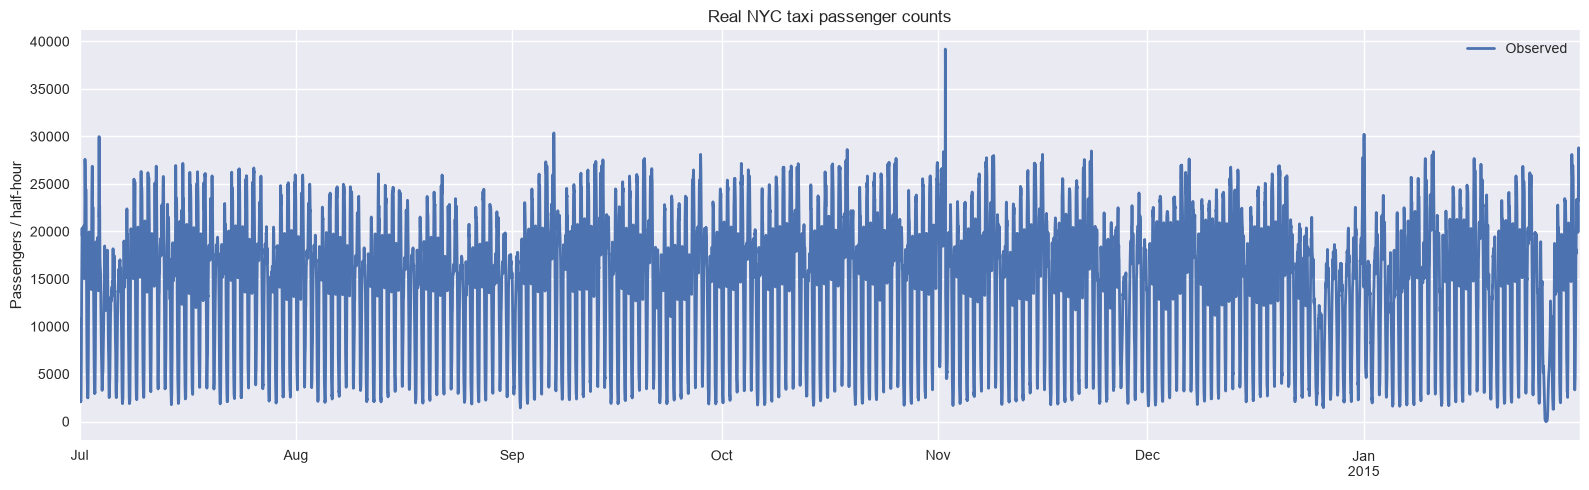

In [10]:
ax = y.plot(linewidth=2, xlabel="", ylabel="Passengers / half-hour",
            title="Real NYC taxi passenger counts", label="Observed")
ax.legend()
plt.tight_layout()
plt.show()

This code snippet generates a simple line plot visualizing the time series data loaded in the previous steps—specifically, the "passengers" column of the NYC taxi dataset.

It uses the `.plot()` method on the Pandas Series `y` (which contains the passenger counts) to create the line plot. The arguments passed to `.plot()` specify: a linewidth of 2, no x-axis label (`xlabel=""`), a y-axis label ("Passengers / half-hour"), a title for the plot ("Real NYC taxi passenger counts"), and a label for the plotted data ("Observed").

The resulting Matplotlib axes object is assigned to the variable `ax`. The code then adds a legend to the plot using `ax.legend()`, displaying the label associated with the line. 

`plt.tight_layout()` adjusts the subplot parameters to provide reasonable spacing between elements of the plot, preventing labels from overlapping. Finally, `plt.show()` displays the generated plot in a new window or inline (depending on the environment). This provides an initial visual inspection of the time series data before any further analysis is performed.

In [11]:
assert y.index.is_unique and y.index.is_monotonic_increasing
expected_index = pd.date_range(y.index.min(), y.index.max(), freq=CFG.frequency)
assert y.index.equals(expected_index), "Inspect missing or irregular timestamps before modeling."
assert y.notna().all() and np.isfinite(y).all() and y.ge(0).all()
audit = pd.Series({
    "observations": len(y), "start": y.index.min(), "end": y.index.max(),
    "missing_values": int(y.isna().sum()), "duplicate_timestamps": int(y.index.duplicated().sum()),
    "sampling_interval": str(STEP),
})
audit

observations                          10320
start                   2014-07-01 00:00:00
end                     2015-01-31 23:30:00
missing_values                            0
duplicate_timestamps                      0
sampling_interval           0 days 00:30:00
dtype: object

This code segment performs a series of data quality checks on the time series `y` (NYC taxi passenger counts) to ensure it's suitable for subsequent modeling and analysis. It also generates an audit report summarizing key characteristics of the dataset.

First, it asserts that the index of the time series is unique and monotonically increasing—meaning each timestamp appears only once and they are in chronological order. This is crucial for time series analysis.

Next, it constructs an `expected_index` using `pd.date_range`, starting from the minimum timestamp in `y` to the maximum timestamp, with a frequency specified by `CFG.frequency` (e.g., "30min"). It then asserts that the actual index of `y` is equal to this expected index. This verifies that there are no missing or irregular timestamps in the dataset. A message prompts inspection if the assertion fails.

The code further asserts that all values in `y` are not missing (`y.notna().all()`), finite (not infinity or NaN—`np.isfinite(y).all()`), and non-negative (`y.ge(0).all()`). These checks ensure data validity and prevent errors during modeling.

Finally, it creates a Pandas Series called `audit` to summarize the key characteristics of the dataset: the number of observations (`len(y)`), the start and end timestamps (`y.index.min()` and `y.index.max()`), the number of missing values (`y.isna().sum()`), the number of duplicate timestamps (`y.index.duplicated().sum()`), and the sampling interval (`STEP`). The audit series is then displayed, providing a concise overview of the dataset's quality and characteristics. This helps to quickly identify any potential issues before proceeding with further analysis.

In [12]:
SERIES_KEY = "realKnownCause/nyc_taxi.csv"
annotation_file = json.loads((data_folder / "nab_combined_windows.json").read_text())
event_windows = pd.DataFrame(annotation_file[SERIES_KEY], columns=["start", "end"])
event_windows = event_windows.apply(pd.to_datetime)
event_windows["event"] = ["NYC marathon", "Thanksgiving", "Christmas", "New Year", "Snowstorm"]
labels = pd.Series(False, index=y.index, name="in_official_window")
for event in event_windows.itertuples(index=False):
    labels.loc[event.start:event.end] = True
print(f"Official windows: {len(event_windows)} | labeled fraction: {labels.mean():.3%}")
event_windows

Official windows: 5 | labeled fraction: 10.029%


,start,end,event
0,2014-10-30 15:30:00,2014-11-03 22:30:00,NYC marathon
1,2014-11-25 12:00:00,2014-11-29 19:00:00,Thanksgiving
2,2014-12-23 11:30:00,2014-12-27 18:30:00,Christmas
3,2014-12-29 21:30:00,2015-01-03 04:30:00,New Year
4,2015-01-24 20:30:00,2015-01-29 03:30:00,Snowstorm


This code segment loads and processes anomaly event annotations for the NYC taxi dataset, creating a boolean time series indicating when events are occurring.

First, it defines `SERIES_KEY` as the key used to access the NYC taxi data within the annotation file. It then reads the JSON file "nab_combined_windows.json" from the data folder and parses it using `json.loads()`. This file contains annotations for various time series datasets, including the NYC taxi dataset.

The code extracts the event windows specifically for the NYC taxi dataset (identified by `SERIES_KEY`) into a Pandas DataFrame called `event_windows`. The DataFrame initially has "start" and "end" columns representing the start and end timestamps of each event window. These timestamps are converted to datetime objects using `pd.to_datetime()`.

A new column named "event" is added to the `event_windows` DataFrame, providing descriptive labels for each event (e.g., "NYC marathon", "Thanksgiving").

Next, a Pandas Series called `labels` is created with all values initialized to False and indexed by the time series index of `y` (the passenger counts). This series will serve as a boolean mask indicating whether each timestamp falls within an official event window. The series is named “in_official_window”.

The code then iterates through each row in the `event_windows` DataFrame using `itertuples(index=False)`. For each event, it sets the corresponding values in the `labels` Series to True for all timestamps within the event's start and end times. This effectively marks the time periods associated with known events.

Finally, the code prints a summary of the annotation data: the number of official windows (`len(event_windows)`) and the fraction of the time series that is labeled as being within an event window (`labels.mean():.3%`). The `event_windows` DataFrame itself is then displayed, showing the start and end times along with the labels for each event. This prepares a ground truth signal to evaluate anomaly detection performance against known events.

In [13]:
train_index = y.index[y.index < pd.Timestamp(CFG.train_end)]
validation_index = y.index[(y.index >= pd.Timestamp(CFG.train_end))
                           & (y.index < pd.Timestamp(CFG.validation_end))]
calibration_index = y.index[(y.index >= pd.Timestamp(CFG.validation_end))
                            & (y.index < pd.Timestamp(CFG.calibration_end))]
test_index = y.index[y.index >= pd.Timestamp(CFG.calibration_end)]
splits = {"train": train_index, "validation": validation_index,
          "calibration": calibration_index, "test": test_index}
assert all(len(index) for index in splits.values())
assert train_index.max() < validation_index.min() < calibration_index.min() < test_index.min()
scores, reports = {}, {}
split_table = pd.DataFrame([
    {"split": name, "start": index.min(), "end": index.max(), "rows": len(index),
     "labeled_rows_for_audit_only": int(labels.loc[index].sum())}
    for name, index in splits.items()
]).set_index("split")
split_table

,start,end,rows,labeled_rows_for_audit_only
split,,,,
train,2014-07-01,2014-08-31 23:30:00,2976,0
validation,2014-09-01,2014-09-30 23:30:00,1440,0
calibration,2014-10-01,2014-10-19 23:30:00,912,0
test,2014-10-20,2015-01-31 23:30:00,4992,1035


This code segment divides the time series data into training, validation, calibration, and test sets based on predefined dates specified in the `CFG` object. It also creates a summary table of these splits for auditing purposes.

First, it defines index boundaries for each split using boolean indexing on the time series index (`y.index`). The `train_index`, `validation_index`, `calibration_index`, and `test_index` are created based on comparisons with timestamps defined in `CFG.train_end`, `CFG.validation_end`, and `CFG.calibration_end`.

A dictionary called `splits` is then created to store these indices, mapping split names ("train", "validation", "calibration", "test") to their corresponding index objects.

Two assertions are performed to ensure the validity of the splits: The first checks that each split contains at least one data point (i.e., no empty splits). The second verifies that the splits are chronologically ordered—the maximum timestamp in the training set is before the minimum timestamp in the validation set, and so on.

Two dictionaries, `scores` and `reports`, are initialized to store evaluation results from different anomaly detection methods later in the code.

Finally, a Pandas DataFrame called `split_table` is created to summarize the characteristics of each split. It includes the split name, start and end timestamps, number of rows (data points), and the number of labeled event rows within that split (for audit purposes). The "split" column is set as the index of the DataFrame. This table provides a clear overview of how the data has been partitioned for model training and evaluation. The `split_table` is then displayed, providing a concise summary of the dataset splits.

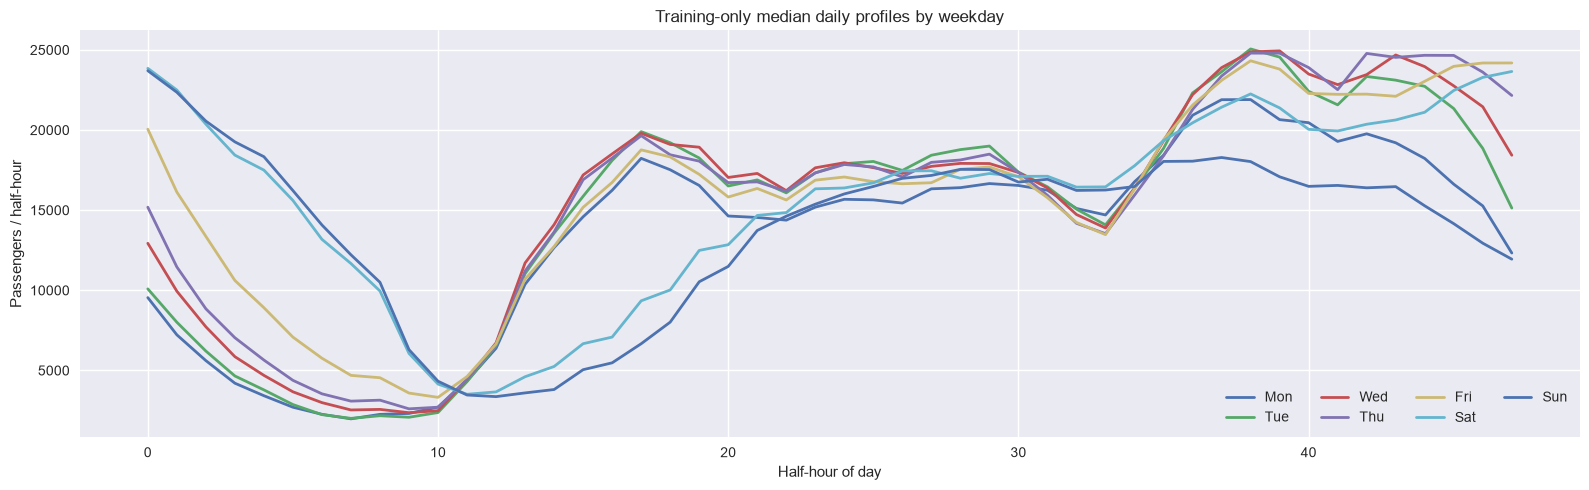

In [14]:
training_calendar = pd.DataFrame({"value": y.loc[train_index]})
training_calendar["slot"] = training_calendar.index.hour * 2 + training_calendar.index.minute // 30
training_calendar["day_of_week"] = training_calendar.index.dayofweek
daily_profiles = training_calendar.groupby(["slot", "day_of_week"])["value"].median().unstack()
daily_profiles.columns = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
ax = daily_profiles.plot(linewidth=2, title="Training-only median daily profiles by weekday",
                         xlabel="Half-hour of day", ylabel="Passengers / half-hour")
ax.legend(ncol=4)
plt.tight_layout()
plt.show()

This code segment calculates and visualizes the average passenger counts for each half-hour slot on each day of the week, based solely on the training data. This is done to create a baseline understanding of typical daily patterns in the time series.

First, it creates a new DataFrame called `training_calendar` containing only the data from the training period (`y.loc[train_index]`). A "slot" column is added, representing the half-hour slot of each observation (0 for 0:00-0:30, 1 for 0:30-1:00, and so on). It’s calculated by multiplying the hour by 2 and adding the integer division of the minute by 30. A "day_of_week" column is added representing the day of the week (0 for Monday, 1 for Tuesday, etc.).

Next, it groups the `training_calendar` DataFrame by both "slot" and "day_of_week" and calculates the median passenger count for each group using `.median()`. The result is then unstacked to create a new DataFrame called `daily_profiles`, where columns represent days of the week ("Mon", "Tue", etc.) and rows represent half-hour slots.

A line plot of `daily_profiles` is generated using Matplotlib, with appropriate labels for the title, x-axis (half-hour of day), and y-axis (passengers per half-hour). The legend is displayed with four columns (`ncol=4`) to improve readability. Finally, `plt.tight_layout()` adjusts the plot layout, and `plt.show()` displays the visualization. This plot reveals typical daily patterns in passenger counts for each day of the week based on the training data alone.

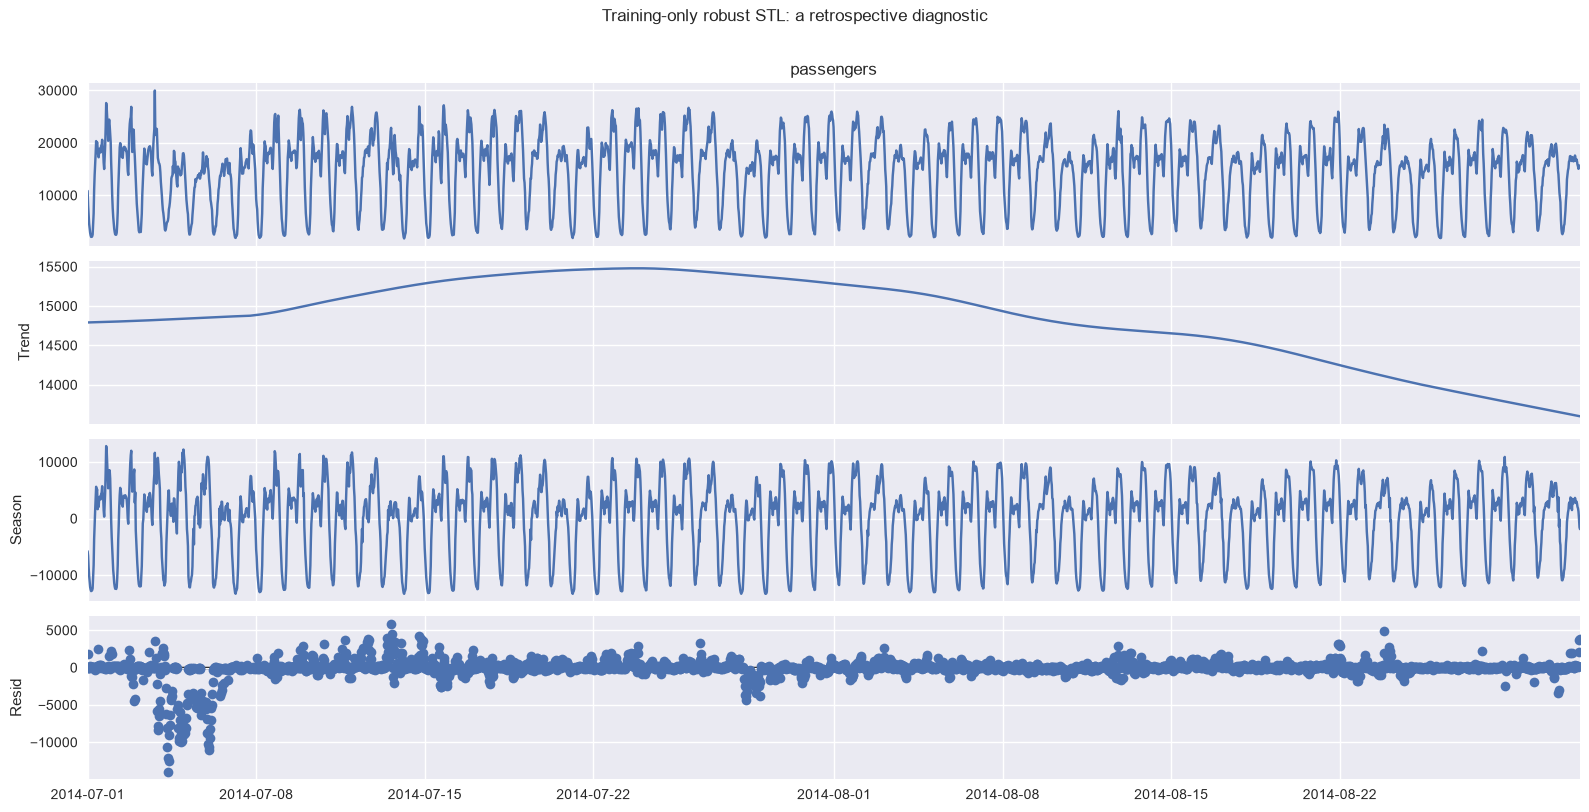

In [15]:
training_stl = STL(y.loc[train_index], period=CFG.weekly_period, robust=True).fit()
fig = training_stl.plot()
fig.set_size_inches(CFG.img_dim1, 8)
fig.suptitle("Training-only robust STL: a retrospective diagnostic", y=1.01)
plt.tight_layout()
plt.show()

This code segment performs Seasonal and Trend decomposition using Loess (STL) on the training data to analyze its underlying components—trend, seasonality, and residuals. This is used as a diagnostic tool to understand the characteristics of the time series before applying more complex modeling techniques.

First, it creates an STL object (`training_stl`) initialized with the training data (`y.loc[train_index]`), a seasonal period defined by `CFG.weekly_period`, and `robust=True` which makes the decomposition less sensitive to outliers. The `.fit()` method then applies the STL algorithm to decompose the time series.

Next, it generates a plot of the decomposed components using `training_stl.plot()`. This plot displays three subplots: the original time series, the estimated trend component, and the estimated seasonal component.

The figure size is set using `fig.set_size_inches()` to match the dimensions defined in `CFG.img_dim1` and a height of 8 inches. A title ("Training-only robust STL: a retrospective diagnostic") is added to the entire figure using `fig.suptitle()`, positioned slightly above the plots (`y=1.01`).

Finally, `plt.tight_layout()` adjusts the plot layout for better spacing, and `plt.show()` displays the resulting decomposition plot. This visualization helps identify any long-term trends, recurring seasonal patterns, and residual noise in the training data, providing valuable insights for model selection and parameter tuning.

# Statistical detectors


## Raw values: a robust global baseline

In [16]:
scores["Raw MAD"] = robust_standardize(y, y.loc[train_index]).abs()
pd.Series({"training_median": y.loc[train_index].median(),
           "training_scaled_MAD": 1.4826 * (y.loc[train_index] - y.loc[train_index].median()).abs().median(),
           "largest_training_score": scores["Raw MAD"].loc[train_index].max()})

training_median           16378.500000
training_scaled_MAD        5164.637100
largest_training_score        2.828756
dtype: float64

This code segment calculates a robust measure of anomaly score based on the Median Absolute Deviation (MAD) and provides summary statistics related to the training data.

First, it computes the "Raw MAD" score by applying the `robust_standardize` function to the entire time series (`y`), using the training data (`y.loc[train_index]`) as the reference for centering and scaling. The absolute value of the standardized residuals is then stored in the `scores` dictionary under the key "Raw MAD". This represents how far each point deviates from the typical behavior observed during the training period, measured in robust scale units.

Next, it creates a Pandas Series containing summary statistics related to the training data:
- `"training_median"`: The median value of the time series during the training period.
- `"training_scaled_MAD"`:  The scaled MAD calculated using the training data—specifically, 1.4826 times the median absolute deviation from the training median. This provides a measure of the typical variability in the training data.
- `"largest_training_score"`: The maximum value of the "Raw MAD" scores within the training period. This indicates the highest degree of deviation observed during training, serving as a benchmark for anomaly detection.

This series is then printed to provide insights into the characteristics of the training data and the scale of the calculated anomaly scores. These statistics are useful for interpreting the magnitude of the "Raw MAD" scores and setting appropriate thresholds for anomaly detection.

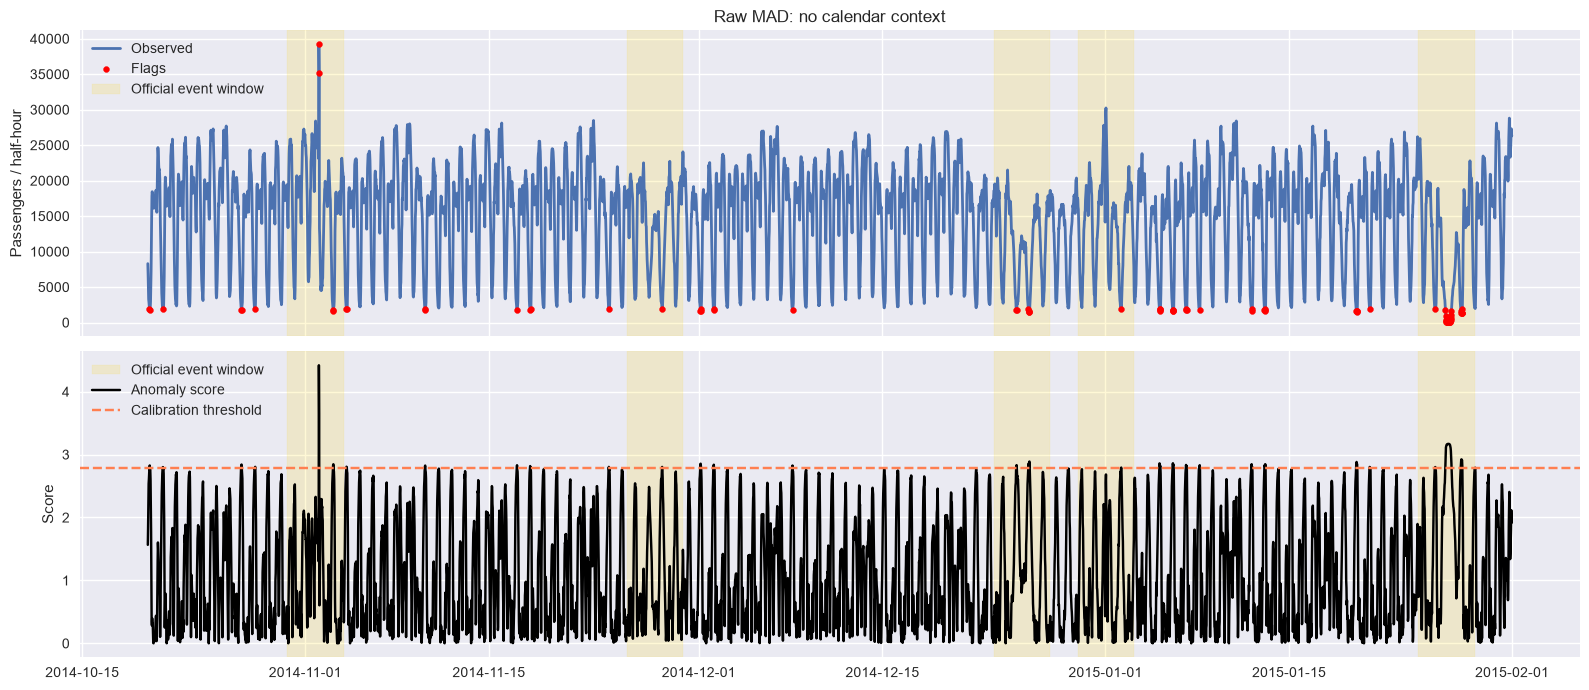

method                        Raw MAD
threshold                     2.79158
calibration_flag_fraction    0.008772
precision                      0.4941
recall                         0.0406
f1                              0.075
average_precision              0.2543
detected_events                     5
events                              5
event_recall                      1.0
median_delay_h_detected          57.5
false_flag_fraction            0.0109
false_runs_per_30d               8.01
dtype: object

In [17]:
reports["Raw MAD"] = evaluate_scores("Raw MAD", scores["Raw MAD"], labels,
                                    calibration_index, test_index, CFG.alpha)
plot_detector(y, labels, scores["Raw MAD"], reports["Raw MAD"]["threshold"],
              test_index, "Raw MAD: no calendar context")
pd.Series(reports["Raw MAD"])

This block Eealuates the performance of the “Raw MAD” anomaly detection method and visualizes its results.

First, it calls the `evaluate_scores` function to assess the effectiveness of the "Raw MAD" scores in identifying true events. The arguments passed include: the name of the method ("Raw MAD"), the calculated "Raw MAD" scores (`scores["Raw MAD"]`), the ground truth event labels (`labels`), the calibration index, the test index, and the significance level `CFG.alpha`. The returned evaluation metrics are stored in the `reports` dictionary under the key "Raw MAD".

Next, it calls the `plot_detector` function to visualize the results of the anomaly detection process. It passes the original time series data (`y`), event labels (`labels`), the “Raw MAD” scores (`scores["Raw MAD"]`), the threshold determined during calibration (obtained from `reports["Raw MAD"]["threshold"]`), the test index, and a title for the plot ("Raw MAD: no calendar context"). This generates a plot showing the time series, anomaly scores, flagged anomalies, and event windows.

Finally, it converts the evaluation metrics stored in `reports["Raw MAD"]` into a Pandas Series and prints it to display a concise summary of the method’s performance—including precision, recall, F1-score, average precision, detected events, and other relevant metrics. This provides a quantitative assessment of how well the “Raw MAD” method performs in detecting anomalies compared to known events.

## Seasonal residuals

In [18]:
calendar_slot = pd.Series(y.index.dayofweek * CFG.daily_period
                          + y.index.hour * 2 + y.index.minute // 30,
                          index=y.index, name="weekly_slot")
seasonal_profile = y.loc[train_index].groupby(calendar_slot.loc[train_index]).median()
assert len(seasonal_profile) == CFG.weekly_period
expected_seasonal = calendar_slot.map(seasonal_profile).rename("expected")
seasonal_residual = (y - expected_seasonal).rename("seasonal_residual")
scores["Seasonal MAD"] = robust_standardize(seasonal_residual,
                                           seasonal_residual.loc[train_index]).abs()
pd.concat([y, expected_seasonal, seasonal_residual], axis=1).head(3)

,passengers,expected,seasonal_residual
timestamp,,,
2014-07-01 00:00:00,10844.0,10089.0,755.0
2014-07-01 00:30:00,8127.0,8009.0,118.0
2014-07-01 01:00:00,6210.0,6210.0,0.0


This code segment calculates anomaly scores by accounting for the typical seasonal patterns in the data and then identifying deviations from those patterns using a robust scaling method.

First, it creates a `calendar_slot` Series representing each timestamp's position within a weekly cycle. It combines the day of the week (multiplied by `CFG.daily_period`), hour (multiplied by 2), and half-hour slot to create a unique integer identifier for each time slot within a week.

Next, it calculates the median passenger count for each calendar slot using only the training data (`y.loc[train_index]`). This creates a `seasonal_profile` Series representing the expected value for each time slot based on historical patterns. An assertion verifies that the length of the seasonal profile matches `CFG.weekly_period`, ensuring all slots are represented.

The code then maps the `seasonal_profile` onto the entire time series (`y`) using the `calendar_slot` Series to create an `expected_seasonal` Series, representing the expected passenger count at each timestamp based on its weekly slot. The difference between the actual values (`y`) and the expected seasonal values (`expected_seasonal`) is calculated to obtain the `seasonal_residual`.

Anomaly scores are then computed by applying the `robust_standardize` function to the `seasonal_residual`, using the training data as a reference for centering and scaling. The absolute value of these standardized residuals is stored in the `scores` dictionary under the key "Seasonal MAD". This represents how much each observation deviates from its expected seasonal pattern, measured in robust scale units.

Finally, it concatenates the original time series (`y`), the expected seasonal values (`expected_seasonal`), and the seasonal residual (`seasonal_residual`) into a single DataFrame and displays the first three rows using `.head(3)`. This allows for a quick inspection of how well the seasonal profile captures the underlying patterns in the data and the magnitude of the residuals.

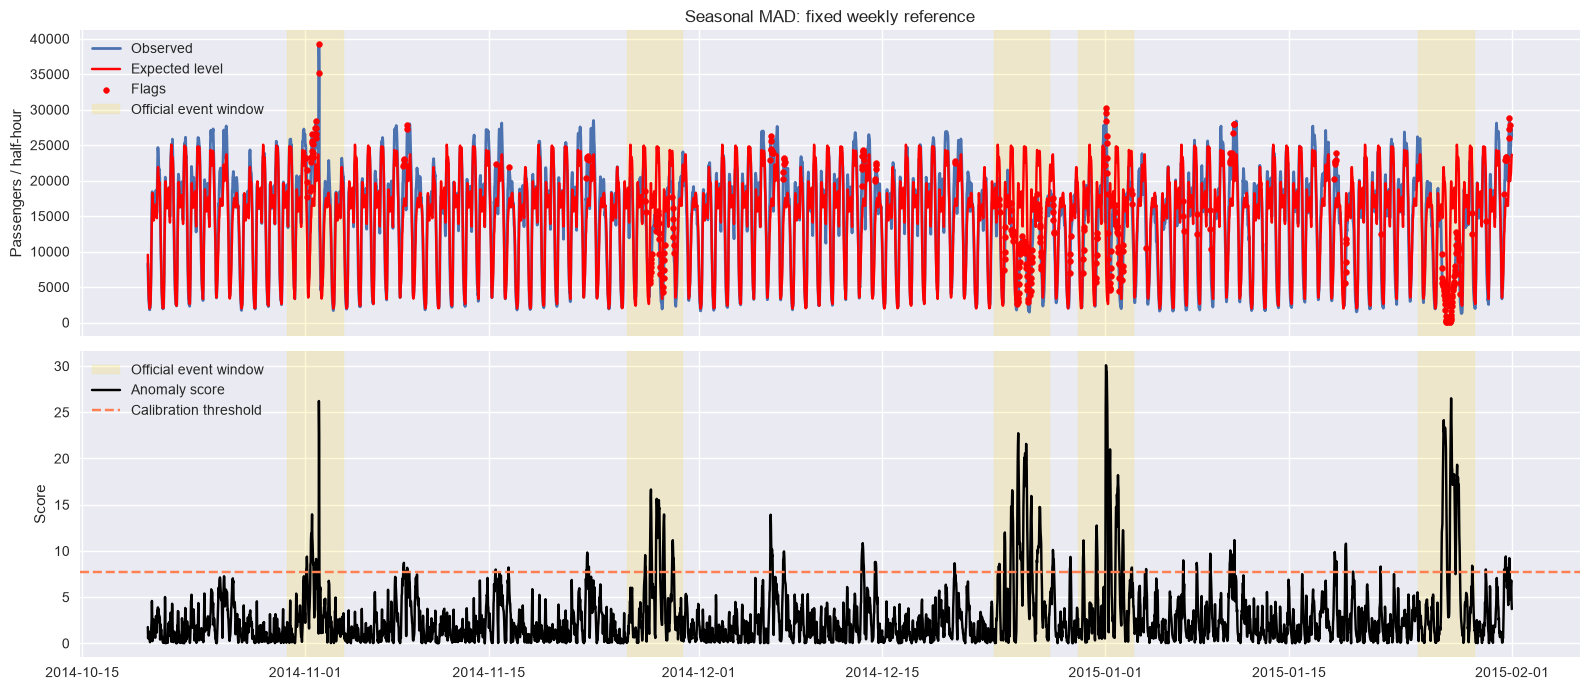

method                       Seasonal MAD
threshold                        7.768952
calibration_flag_fraction        0.008772
precision                          0.7235
recall                             0.2502
f1                                 0.3719
average_precision                  0.4976
detected_events                         5
events                                  5
event_recall                          1.0
median_delay_h_detected              33.5
false_flag_fraction                 0.025
false_runs_per_30d                  12.01
dtype: object

In [19]:
reports["Seasonal MAD"] = evaluate_scores("Seasonal MAD", scores["Seasonal MAD"], labels,
                                         calibration_index, test_index, CFG.alpha)
plot_detector(y, labels, scores["Seasonal MAD"], reports["Seasonal MAD"]["threshold"],
              test_index, "Seasonal MAD: fixed weekly reference", baseline=expected_seasonal)
pd.Series(reports["Seasonal MAD"])

This code segment evaluates the performance of the “Seasonal MAD” anomaly detection method and visualizes its results, including a comparison to the expected seasonal pattern.

First, it calls the `evaluate_scores` function to assess the effectiveness of the "Seasonal MAD" scores in identifying true events. The arguments passed include: the name of the method ("Seasonal MAD"), the calculated "Seasonal MAD" scores (`scores["Seasonal MAD"]`), the ground truth event labels (`labels`), the calibration index, the test index, and the significance level `CFG.alpha`. The returned evaluation metrics are stored in the `reports` dictionary under the key "Seasonal MAD".

Next, it calls the `plot_detector` function to visualize the results of the anomaly detection process. It passes the original time series data (`y`), event labels (`labels`), the “Seasonal MAD” scores (`scores["Seasonal MAD"]`), the threshold determined during calibration (obtained from `reports["Seasonal MAD"]["threshold"]`), the test index, and a title for the plot ("Seasonal MAD: fixed weekly reference"). Importantly, it also passes the `expected_seasonal` Series as the `baseline` argument. This allows the plot to display the expected seasonal pattern alongside the observed data and anomaly scores, providing context for interpreting the results.

Finally, it converts the evaluation metrics stored in `reports["Seasonal MAD"]` into a Pandas Series and prints it to display a concise summary of the method’s performance—including precision, recall, F1-score, average precision, detected events, and other relevant metrics. This provides a quantitative assessment of how well the “Seasonal MAD” method performs in detecting anomalies compared to known events, while also considering seasonal patterns.

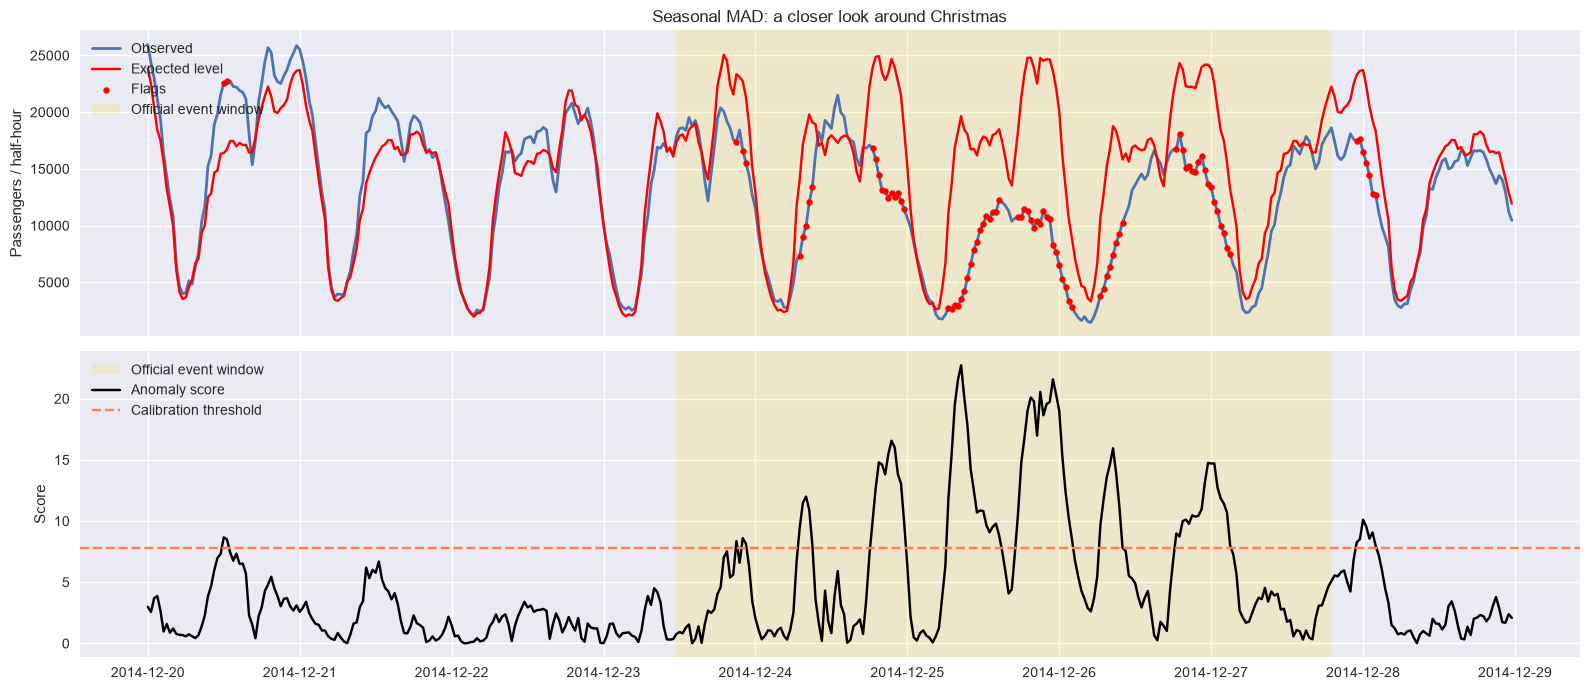

In [20]:
VIEW_START, VIEW_END = "2014-12-20", "2014-12-29"
detail_index = test_index[(test_index >= pd.Timestamp(VIEW_START))
                          & (test_index < pd.Timestamp(VIEW_END))]
plot_detector(y, labels, scores["Seasonal MAD"], reports["Seasonal MAD"]["threshold"],
              detail_index, "Seasonal MAD: a closer look around Christmas", baseline=expected_seasonal)

This code segment focuses on a detailed visualization of the anomaly detection results during a specific period—around Christmas—to provide a more in-depth analysis.

First, it defines `VIEW_START` and `VIEW_END` as strings representing the start and end dates for the detailed view (December 20th to December 29th). It then creates a new index called `detail_index` by selecting timestamps from the test index that fall within this date range.

Next, it calls the `plot_detector` function again, but this time using the `detail_index` instead of the entire test index. This limits the plot to the specified period around Christmas. The arguments passed are similar to previous calls: the original time series data (`y`), event labels (`labels`), the “Seasonal MAD” scores (`scores["Seasonal MAD"]`), the threshold determined during calibration (obtained from `reports["Seasonal MAD"]["threshold"]`), a title for the plot ("Seasonal MAD: a closer look around Christmas"), and the expected seasonal pattern as the baseline.

This generates a focused visualization of the anomaly detection results specifically for the Christmas period, allowing for a more detailed examination of how well the method performs during this potentially anomalous time. The inclusion of the `expected_seasonal` baseline helps to understand whether detected anomalies are due to deviations from typical seasonal patterns or truly unusual events.

## Forecast residuals: add the most recent observations

In [21]:
LAGS = [1, 2, CFG.daily_period, 2 * CFG.daily_period, CFG.weekly_period]
forecast_features = pd.DataFrame({f"lag_{lag}": y.shift(lag) for lag in LAGS})
forecast_features["weekly_expected"] = expected_seasonal
forecast_frame = forecast_features.join(y).dropna()
forecast_train = forecast_frame.index.intersection(train_index)
forecast_validation = forecast_frame.index.intersection(validation_index)
assert forecast_train.max() < forecast_validation.min()
forecast_frame.head(3)

,lag_1,lag_2,lag_48,lag_96,lag_336,weekly_expected,passengers
timestamp,,,,,,,
2014-07-08 00:00:00,11849.0,14955.0,8675.0,15427.0,10844.0,10089.0,9292.0
2014-07-08 00:30:00,9292.0,11849.0,7180.0,14615.0,8127.0,8009.0,8110.0
2014-07-08 01:00:00,8110.0,9292.0,5178.0,13124.0,6210.0,6210.0,7352.0


This code segment prepares data for a forecasting model, creating features based on lagged values of the time series and the expected seasonal component.

First, it defines a list called `LAGS` containing integer values representing different lag periods—1, 2, `CFG.daily_period`, 2 * `CFG.daily_period`, and `CFG.weekly_period`. These lags will be used as input features for the forecasting model.

Next, it creates a Pandas DataFrame called `forecast_features` by generating lagged versions of the time series (`y`) using the `.shift()` method. For each lag in the `LAGS` list, a new column is added to the DataFrame with the name "lag_{lag}" containing the shifted values. It also adds a column named “weekly_expected” containing the expected seasonal component calculated earlier.

The `forecast_features` DataFrame is then joined with the original time series (`y`) using `.join()`, creating a combined DataFrame called `forecast_frame`. Rows with missing values (resulting from the shifting operation) are removed using `.dropna()`.

The code then defines training and validation indices by finding the intersection between the index of `forecast_frame` and the previously defined `train_index` and `validation_index`, respectively. This ensures that only data points present in both the forecast frame and the original splits are used for training and validation. An assertion verifies that the training and validation sets do not overlap.

Finally, it displays the first three rows of the `forecast_frame` using `.head(3)` to provide a preview of the prepared dataset, showing the lagged features, seasonal component, and target variable. This prepares the data for building and evaluating a forecasting model that can predict future values based on past observations and seasonal patterns.

In [22]:
ridge_candidates, ridge_rows = {}, []
for alpha in CFG.ridge_alphas:
    model = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    model.fit(forecast_features.loc[forecast_train], y.loc[forecast_train])
    validation_prediction = model.predict(forecast_features.loc[forecast_validation])
    ridge_candidates[alpha] = model
    ridge_rows.append({"alpha": alpha,
                       "validation_rmse": float(np.sqrt(mean_squared_error(
                           y.loc[forecast_validation], validation_prediction)))})
ridge_tuning = pd.DataFrame(ridge_rows).set_index("alpha")
selected_alpha = float(ridge_tuning["validation_rmse"].idxmin())
ridge_model = ridge_candidates[selected_alpha]
print(f"Manual reference: alpha=1.0 | validation-selected alpha={selected_alpha}")
ridge_tuning.round(2)

Manual reference: alpha=1.0 | validation-selected alpha=0.1


,validation_rmse
alpha,
0.1,1298.47
1.0,1304.91
10.0,1351.14
100.0,1465.84


This code segment performs hyperparameter tuning for a Ridge regression model using cross-validation to find the optimal regularization strength (alpha).

First, it initializes two dictionaries, `ridge_candidates` and an empty list called `ridge_rows`. The `ridge_candidates` dictionary will store trained Ridge models for each alpha value tested. The `ridge_rows` list will accumulate results from each model’s validation performance.

The code then iterates through the different alpha values specified in `CFG.ridge_alphas`. For each alpha, it creates a pipeline consisting of a StandardScaler (for feature scaling) and a Ridge regression model with the current alpha value. The pipeline is trained on the training data (`forecast_train`) using the features from `forecast_features` and the target variable `y`.

Next, it makes predictions on the validation data (`forecast_validation`) using the trained model. It calculates the Root Mean Squared Error (RMSE) between the predicted values and the actual values in the validation set. The alpha value, along with its corresponding RMSE, is stored in the `ridge_rows` list as a dictionary.

After iterating through all alpha values, it creates a Pandas DataFrame called `ridge_tuning` from the `ridge_rows` list, setting the "alpha" column as the index. This DataFrame summarizes the validation performance of each Ridge model with different alpha values.

The code then selects the alpha value that resulted in the lowest RMSE on the validation set using `.idxmin()`. The corresponding trained Ridge model is retrieved from the `ridge_candidates` dictionary and assigned to `ridge_model`. A message is printed indicating the manually chosen reference alpha (1.0) and the validation-selected optimal alpha.

Finally, it displays the `ridge_tuning` DataFrame, rounded to two decimal places, providing a clear overview of the model’s performance with different regularization strengths. This allows for comparison and selection of the best performing Ridge regression model based on its validation RMSE.

In [23]:
forecast = pd.Series(ridge_model.predict(forecast_features.loc[forecast_frame.index]),
                     index=forecast_frame.index, name="one_step_forecast")
forecast_residual = (y.reindex(forecast.index) - forecast).rename("forecast_residual")
scores["Ridge residual"] = forecast_residual.abs()
ridge_coefficients = pd.Series(ridge_model.named_steps["ridge"].coef_,
                               index=forecast_features.columns, name="scaled_feature_coefficient")
pd.concat([y, forecast, forecast_residual], axis=1).loc[validation_index].head(3)

,passengers,one_step_forecast,forecast_residual
timestamp,,,
2014-09-01 00:00:00,14618.0,12277.490083,2340.509917
2014-09-01 00:30:00,12908.0,10358.367462,2549.632538
2014-09-01 01:00:00,10842.0,8481.282967,2360.717033


This code segment generates a one-step ahead forecast using the tuned Ridge regression model and calculates the residual errors. It also extracts the coefficients of the fitted Ridge model to understand feature importance.

First, it uses the trained `ridge_model` to predict values for all time points in the `forecast_frame`. The predictions are stored in a Pandas Series called `forecast`, indexed by the index of `forecast_frame`.

Next, it calculates the residual errors by subtracting the forecast from the actual observed values (`y`). The residuals are reindexed to match the forecast’s index and renamed “forecast_residual”. Anomaly scores based on the absolute value of these residuals are stored in the `scores` dictionary under the key "Ridge residual".

The code then extracts the coefficients of the Ridge regression model from its internal steps (accessed via `ridge_model.named_steps["ridge"].coef_`) and stores them in a Pandas Series called `ridge_coefficients`. The columns of the `forecast_features` DataFrame are used as the index for this series, providing information about the importance of each feature in the model.

Finally, it concatenates the original time series (`y`), the forecast values, and the residual errors into a single DataFrame and displays the first three rows corresponding to the validation index using `.loc[validation_index].head(3)`. This allows for a quick inspection of the forecast accuracy and the magnitude of the residuals during the validation period.

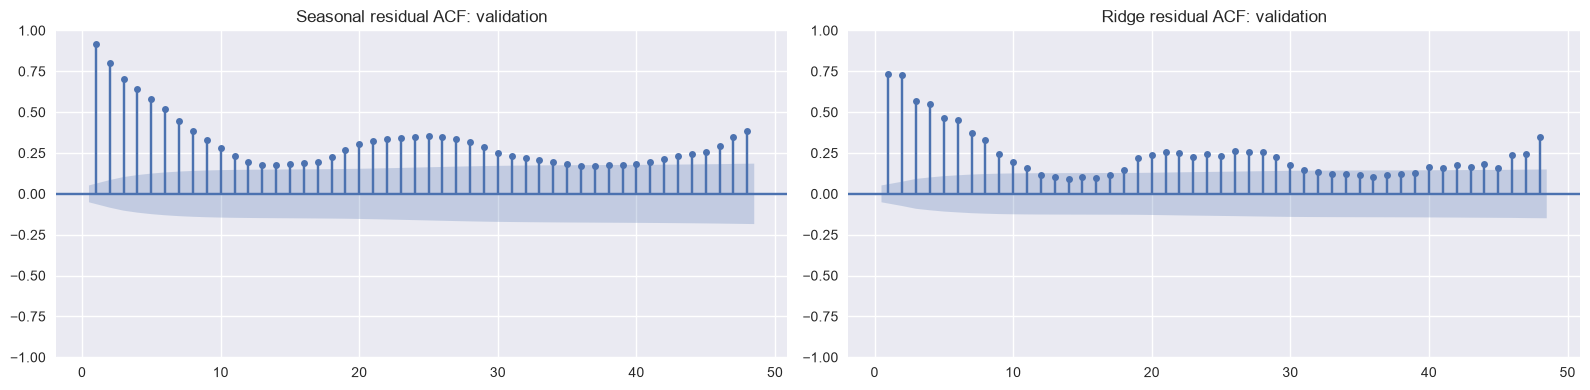

In [24]:
ACF_LAGS = CFG.daily_period
fig, axes = plt.subplots(1, 2, figsize=(CFG.img_dim1, 4))
plot_acf(seasonal_residual.loc[validation_index], lags=ACF_LAGS, zero=False, ax=axes[0])
plot_acf(forecast_residual.loc[forecast_validation], lags=ACF_LAGS, zero=False, ax=axes[1])
axes[0].set_title("Seasonal residual ACF: validation")
axes[1].set_title("Ridge residual ACF: validation")
plt.tight_layout()
plt.show()

This code segment visualizes the Autocorrelation Function (ACF) of both the seasonal residuals and the forecast residuals to assess whether there is any remaining autocorrelation in these error terms after modeling.

First, it defines `ACF_LAGS` as equal to `CFG.daily_period`, specifying the maximum number of lags to be displayed in the ACF plots. It then creates a figure with two subplots using Matplotlib.

The code uses the `plot_acf` function from `statsmodels.graphics.tsaplots` to generate ACF plots for both the seasonal residual (`seasonal_residual`) and the forecast residual (`forecast_residual`). The `lags` argument is set to `ACF_LAGS`, limiting the displayed lags. `zero=False` prevents a vertical line at lag zero, making it easier to interpret the plot. Each ACF plot is drawn on one of the subplots (axes[0] and axes[1], respectively).

The titles of each subplot are set to indicate which residual series is being plotted ("Seasonal residual ACF: validation" and "Ridge residual ACF: validation"). The plots focus on the validation period for both residuals.

Finally, `plt.tight_layout()` adjusts the spacing between subplots, and `plt.show()` displays the generated ACF plots. These plots help determine if there's any remaining serial correlation in the errors after removing seasonal patterns and applying the Ridge regression model. If significant autocorrelation remains, it suggests that further modeling or adjustments may be needed to capture underlying dependencies in the data.

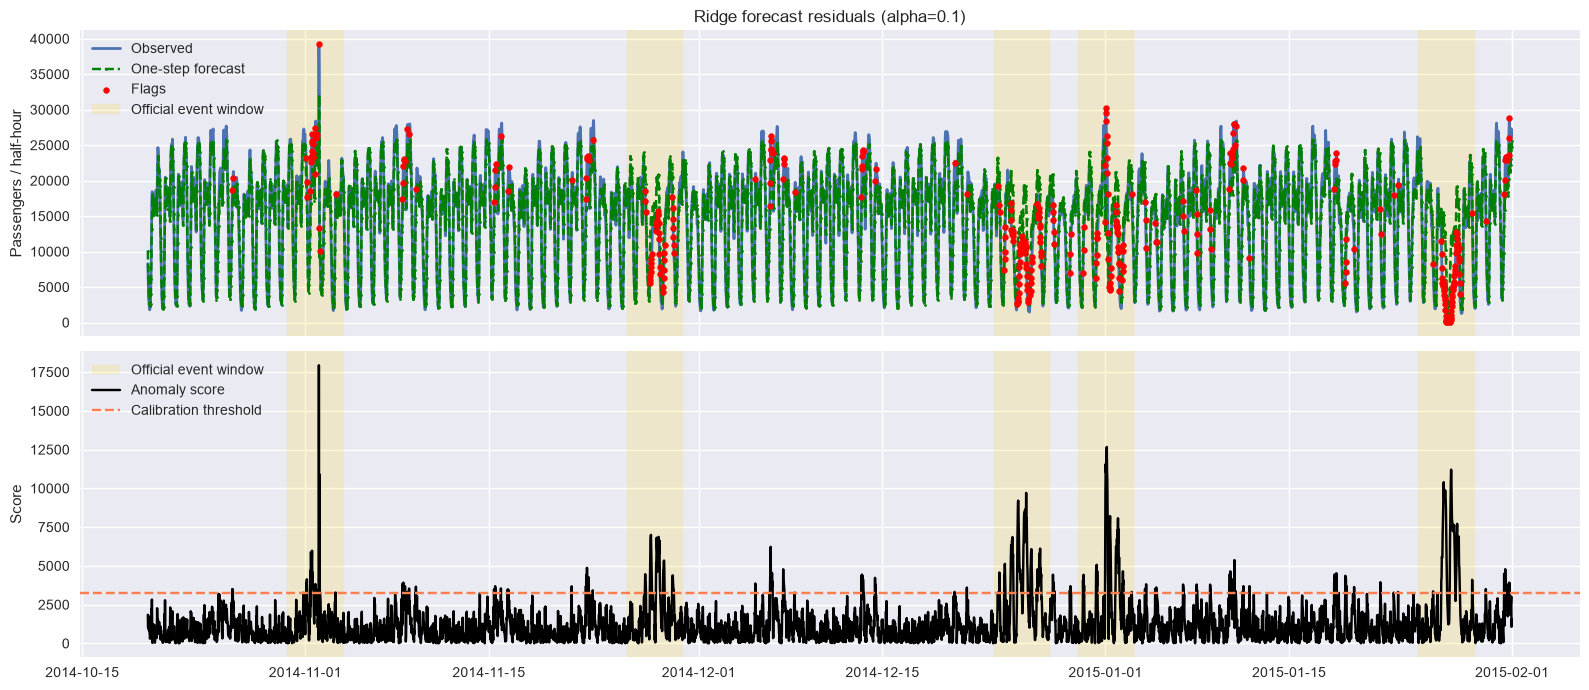

method                       Ridge residual
threshold                       3266.307095
calibration_flag_fraction          0.008772
precision                            0.6812
recall                               0.2415
f1                                   0.3566
average_precision                    0.4791
detected_events                           5
events                                    5
event_recall                            1.0
median_delay_h_detected                27.0
false_flag_fraction                  0.0296
false_runs_per_30d                    29.48
dtype: object

In [25]:
reports["Ridge residual"] = evaluate_scores("Ridge residual", scores["Ridge residual"], labels,
                                           calibration_index, test_index, CFG.alpha)
plot_detector(y, labels, scores["Ridge residual"], reports["Ridge residual"]["threshold"],
              test_index, f"Ridge forecast residuals (alpha={selected_alpha})", forecast=forecast)
pd.Series(reports["Ridge residual"])

This code segment evaluates the performance of anomaly detection based on the Ridge regression forecast residuals and visualizes the results, including a comparison to the actual forecasts.

First, it calls the `evaluate_scores` function to assess the effectiveness of the "Ridge residual" scores in identifying true events. The arguments passed include: the name of the method ("Ridge residual"), the calculated "Ridge residual" scores (`scores["Ridge residual"]`), the ground truth event labels (`labels`), the calibration index, the test index, and the significance level `CFG.alpha`. The returned evaluation metrics are stored in the `reports` dictionary under the key "Ridge residual".

Next, it calls the `plot_detector` function to visualize the results of the anomaly detection process. It passes the original time series data (`y`), event labels (`labels`), the “Ridge residual” scores (`scores["Ridge residual"]`), the threshold determined during calibration (obtained from `reports["Ridge residual"]["threshold"]`), the test index, and a title for the plot that includes the selected alpha value (`f"Ridge forecast residuals (alpha={selected_alpha})"`) . Importantly, it also passes the `forecast` Series as the `forecast` argument. This allows the plot to display the forecasts alongside the observed data, anomaly scores, and event windows, providing context for interpreting the results.

Finally, it converts the evaluation metrics stored in `reports["Ridge residual"]` into a Pandas Series and prints it to display a concise summary of the method’s performance—including precision, recall, F1-score, average precision, detected events, and other relevant metrics. This provides a quantitative assessment of how well anomaly detection based on the Ridge regression forecast residuals performs in detecting anomalies compared to known events.

## EWMA: add memory to contextual residuals

In [26]:
signed_context = robust_standardize(seasonal_residual, seasonal_residual.loc[train_index])
ewma = signed_context.ewm(alpha=CFG.ewma_alpha, adjust=False).mean()
scores["Seasonal EWMA"] = ewma.abs()
pd.DataFrame({"signed_context": signed_context, "ewma": ewma}).loc[validation_index].head(3)

,signed_context,ewma
timestamp,,
2014-09-01 00:00:00,7.136661,1.198817
2014-09-01 00:30:00,7.996127,1.878548
2014-09-01 01:00:00,7.354692,2.426163


This code segment calculates anomaly scores based on an Exponentially Weighted Moving Average (EWMA) of the standardized seasonal residuals.

First, it applies the `robust_standardize` function to the `seasonal_residual`, using the training data as a reference for centering and scaling. This results in a series called `signed_context`, representing deviations from the typical seasonal behavior in robust scale units.

Next, it calculates an EWMA of the `signed_context` series using the `.ewm()` method. The `alpha` parameter is set to `CFG.ewma_alpha`, controlling the weighting given to recent observations (a smaller alpha gives more weight to older data). `adjust=False` prevents the initial weights from being adjusted, ensuring consistent behavior. The resulting EWMA series is stored in the variable `ewma`.

Anomaly scores are then calculated by taking the absolute value of the `ewma` and storing them in the `scores` dictionary under the key "Seasonal EWMA". This represents how much each observation deviates from its recent historical pattern, smoothed using the EWMA.

Finally, it creates a Pandas DataFrame containing both the `signed_context` and `ewma` series and displays the first three rows corresponding to the validation index using `.loc[validation_index].head(3)`. This allows for a quick inspection of how the EWMA smooths the standardized residuals and the resulting anomaly scores.

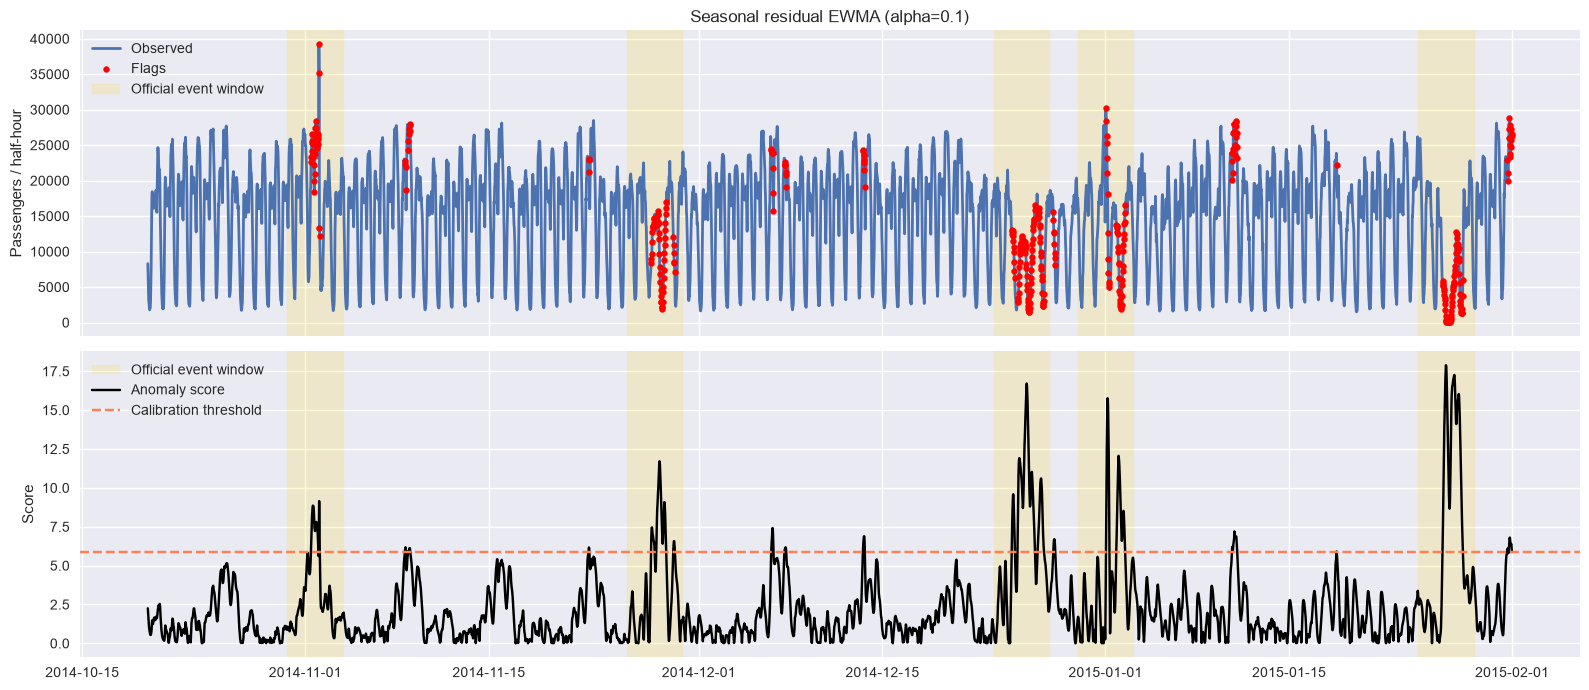

method                       Seasonal EWMA
threshold                         5.857539
calibration_flag_fraction         0.008772
precision                           0.7923
recall                              0.2986
f1                                  0.4337
average_precision                   0.5678
detected_events                          5
events                                   5
event_recall                           1.0
median_delay_h_detected               44.5
false_flag_fraction                 0.0205
false_runs_per_30d                    4.37
dtype: object

In [27]:
reports["Seasonal EWMA"] = evaluate_scores("Seasonal EWMA", scores["Seasonal EWMA"], labels,
                                          calibration_index, test_index, CFG.alpha)
plot_detector(y, labels, scores["Seasonal EWMA"], reports["Seasonal EWMA"]["threshold"],
              test_index, f"Seasonal residual EWMA (alpha={CFG.ewma_alpha})")
pd.Series(reports["Seasonal EWMA"])

This code segment evaluates the performance of anomaly detection based on the Seasonal Exponentially Weighted Moving Average (EWMA) scores and visualizes the results.

First, it calls the `evaluate_scores` function to assess the effectiveness of the "Seasonal EWMA" scores in identifying true events. The arguments passed include: the name of the method ("Seasonal EWMA"), the calculated "Seasonal EWMA" scores (`scores["Seasonal EWMA"]`), the ground truth event labels (`labels`), the calibration index, the test index, and the significance level `CFG.alpha`. The returned evaluation metrics are stored in the `reports` dictionary under the key "Seasonal EWMA".

Next, it calls the `plot_detector` function to visualize the results of the anomaly detection process. It passes the original time series data (`y`), event labels (`labels`), the “Seasonal EWMA” scores (`scores["Seasonal EWMA"]`), the threshold determined during calibration (obtained from `reports["Seasonal EWMA"]["threshold"]`), the test index, and a title for the plot that includes the EWMA alpha value (`f"Seasonal residual EWMA (alpha={CFG.ewma_alpha})"`) .

Finally, it converts the evaluation metrics stored in `reports["Seasonal EWMA"]` into a Pandas Series and prints it to display a concise summary of the method’s performance—including precision, recall, F1-score, average precision, detected events, and other relevant metrics. This provides a quantitative assessment of how well anomaly detection based on the Seasonal EWMA performs in detecting anomalies compared to known events.

# Learned temporal detectors


## Isolation Forest

In [28]:
temporal_features = pd.DataFrame({
    "context": signed_context,
    "recent_mean": signed_context.rolling(CFG.feature_window).mean(),
    "recent_std": signed_context.rolling(CFG.feature_window).std(),
    "daily_mean": signed_context.rolling(CFG.daily_period).mean(),
    "change": signed_context.diff(),
}).dropna()
forest_train = temporal_features.index.intersection(train_index)
forest = IsolationForest(n_estimators=CFG.n_trees, max_samples="auto",
                         contamination="auto", random_state=CFG.SEED, n_jobs=-1)
forest.fit(temporal_features.loc[forest_train])
temporal_features.loc[forest_train].describe().round(3)

,context,recent_mean,recent_std,daily_mean,change
count,2929.000,2929.000,2929.000,2929.000,2929.000
mean,-0.247,-0.249,0.657,-0.235,0.001
std,2.018,1.842,0.610,1.466,0.908
min,-18.267,-14.790,0.016,-7.669,-11.930
25%,-0.710,-0.632,0.298,-0.758,-0.384
50%,0.000,-0.014,0.489,-0.005,0.000
75%,0.637,0.639,0.787,0.678,0.366
max,7.506,4.857,5.678,1.761,8.292


This code segment prepares features for an Isolation Forest anomaly detection model and trains the model on the training data.

First, it creates a Pandas DataFrame called `temporal_features` containing several time-series features derived from the `signed_context` series (the standardized seasonal residuals). These features include:
- `"context"`: The original signed context values.
- `"recent_mean"`: A rolling mean of the signed context over a window defined by `CFG.feature_window`.
- `"recent_std"`: A rolling standard deviation of the signed context over the same window.
- `"daily_mean"`: A rolling mean of the signed context over a period equal to `CFG.daily_period`.
- `"change"`: The first difference of the signed context, representing the change in value from one time step to the next.

Rows with missing values (resulting from the rolling window calculations) are removed using `.dropna()`.

Next, it determines the training indices by finding the intersection between the index of `temporal_features` and the previously defined `train_index`. This ensures that only data points present in both datasets are used for training.

An Isolation Forest model is then initialized with parameters specified in `CFG`, including the number of trees (`n_estimators`), maximum sample size ("auto"), contamination parameter ("auto" lets the algorithm determine it), random state for reproducibility, and parallel processing using all available cores (`n_jobs=-1`). The model is trained on the training data (`temporal_features.loc[forest_train]`) using `.fit()`.

Finally, a descriptive statistics summary of the features used for training (located in `temporal_features.loc[forest_train]`) is calculated and displayed, rounded to three decimal places. This provides insights into the distribution of each feature within the training data.

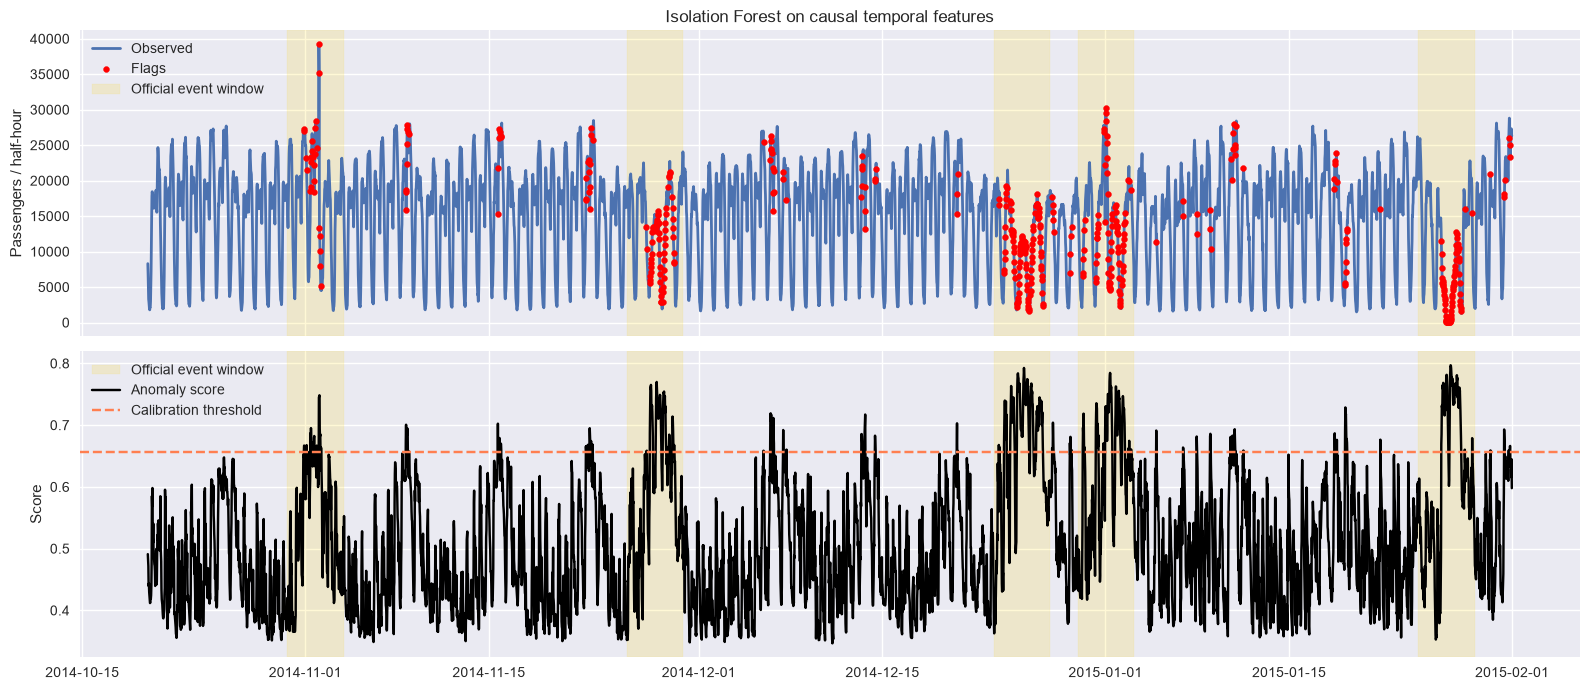

method                       Isolation Forest
threshold                            0.656553
calibration_flag_fraction            0.008772
precision                              0.7654
recall                                 0.3372
f1                                     0.4681
average_precision                      0.6074
detected_events                             5
events                                      5
event_recall                              1.0
median_delay_h_detected                  30.0
false_flag_fraction                     0.027
false_runs_per_30d                      16.74
dtype: object

In [29]:
scores["Isolation Forest"] = pd.Series(-forest.score_samples(temporal_features),
                                        index=temporal_features.index)
reports["Isolation Forest"] = evaluate_scores("Isolation Forest", scores["Isolation Forest"], labels,
                                             calibration_index, test_index, CFG.alpha)
plot_detector(y, labels, scores["Isolation Forest"], reports["Isolation Forest"]["threshold"],
              test_index, "Isolation Forest on causal temporal features")
pd.Series(reports["Isolation Forest"])

This code segment calculates anomaly scores using the trained Isolation Forest model, evaluates its performance, and visualizes the results.

First, it uses the trained `forest` model to calculate anomaly scores for all data points in the `temporal_features` DataFrame using `.score_samples()`. The score samples represent a measure of how anomalous each point is—lower scores indicate higher anomaly likelihood. Since Isolation Forest returns scores where higher values mean more normal, the code negates these scores (`-forest.score_samples(...)`) to ensure that higher scores correspond to anomalies. These negated scores are stored in a Pandas Series called `scores["Isolation Forest"]`, indexed by the index of `temporal_features`.

Next, it calls the `evaluate_scores` function to assess the effectiveness of the "Isolation Forest" anomaly scores in identifying true events. The arguments passed include: the name of the method ("Isolation Forest"), the calculated anomaly scores (`scores["Isolation Forest"]`), the ground truth event labels (`labels`), the calibration index, the test index, and the significance level `CFG.alpha`. The returned evaluation metrics are stored in the `reports` dictionary under the key "Isolation Forest".

Then, it calls the `plot_detector` function to visualize the results of the anomaly detection process. It passes the original time series data (`y`), event labels (`labels`), the “Isolation Forest” scores (`scores["Isolation Forest"]`), the threshold determined during calibration (obtained from `reports["Isolation Forest"]["threshold"]`), the test index, and a title for the plot ("Isolation Forest on causal temporal features").

Finally, it converts the evaluation metrics stored in `reports["Isolation Forest"]` into a Pandas Series and prints it to display a concise summary of the method’s performance—including precision, recall, F1-score, average precision, detected events, and other relevant metrics. This provides a quantitative assessment of how well anomaly detection using the Isolation Forest performs in detecting anomalies compared to known events.

## PCA reconstruction

In [30]:
window_scaler = StandardScaler().fit(y.loc[train_index].to_numpy().reshape(-1, 1))
scaled_y = pd.Series(window_scaler.transform(y.to_numpy().reshape(-1, 1)).ravel(),
                     index=y.index, name="globally_scaled_passengers")
X_windows, window_index = make_windows(scaled_y, CFG.window_size)
window_train_mask = window_index < pd.Timestamp(CFG.train_end)
window_validation_mask = ((window_index - (CFG.window_size - 1) * STEP >= pd.Timestamp(CFG.train_end))
                          & (window_index < pd.Timestamp(CFG.validation_end)))
assert window_train_mask.any() and window_validation_mask.any()
print(f"Windows: {X_windows.shape} | train: {window_train_mask.sum()} | purged validation: {window_validation_mask.sum()}")
pd.DataFrame(X_windows[:3, :5], index=window_index[:3],
             columns=[f"first_lag_position_{i}" for i in range(5)])

Windows: (10273, 48) | train: 2929 | purged validation: 1393


,first_lag_position_0,first_lag_position_1,first_lag_position_2,first_lag_position_3,first_lag_position_4
timestamp,,,,,
2014-07-01 23:30:00,-0.608252,-1.027351,-1.323050,-1.562756,-1.691710
2014-07-02 00:00:00,-1.027351,-1.323050,-1.562756,-1.691710,-1.837785
2014-07-02 00:30:00,-1.323050,-1.562756,-1.691710,-1.837785,-1.915527


This code segment prepares data for a supervised learning model by creating sliding windows of scaled time series values and defining training and validation masks.

First, it creates a `StandardScaler` object and fits it to the training data (`y.loc[train_index]`). The training data is reshaped into a two-dimensional array with one feature (the passenger count) per sample. This ensures that scaling is based only on the training data to avoid data leakage.

Next, it applies the fitted scaler to transform the entire time series `y` using `.transform()`. The transformed values are flattened using `.ravel()` and stored in a Pandas Series called `scaled_y`, indexed by the original index of `y`. This results in a scaled version of the passenger count data.

The code then uses the `make_windows` function to create sliding windows from the `scaled_y` series, with a window size specified by `CFG.window_size`. The function returns two values: `X_windows`, which is a NumPy array containing the sliding windows, and `window_index`, which contains the index corresponding to the end of each window.

Training and validation masks are created based on the `window_index` and the predefined split dates (`CFG.train_end` and `CFG.validation_end`). The `window_train_mask` identifies windows that fall entirely within the training period, while the `window_validation_mask` identifies windows that fall within the validation period after accounting for the window size.

An assertion verifies that both training and validation masks contain at least one True value, ensuring there are data points in both sets. A message is printed indicating the total number of windows created, as well as the number of windows assigned to the training and validation sets.

Finally, a Pandas DataFrame is created displaying the first three rows and five columns of `X_windows`, indexed by the corresponding values from `window_index`. The column names are formatted to indicate the position within each window (e.g., "first_lag_position_0"). This provides a preview of the prepared data for supervised learning.

In [31]:
pca = PCA(n_components=CFG.latent_dim, svd_solver="full")
pca.fit(X_windows[window_train_mask])
pca_reconstruction = pca.inverse_transform(pca.transform(X_windows))
scores["PCA reconstruction"] = pd.Series(
    np.mean((X_windows - pca_reconstruction) ** 2, axis=1), index=window_index
)
pd.Series({"components": pca.n_components_,
           "training_variance_explained": float(pca.explained_variance_ratio_.sum()),
           "validation_reconstruction_MSE": float(scores["PCA reconstruction"].loc[
               window_index[window_validation_mask]].mean())})

components                       8.000000
training_variance_explained      0.963295
validation_reconstruction_MSE    0.046587
dtype: float64

This code segment performs Principal Component Analysis (PCA) on the sliding window data to reduce dimensionality and then uses the reconstruction error as an anomaly score.

First, it creates a PCA object with `n_components` set to `CFG.latent_dim`, specifying the number of principal components to retain. The `svd_solver` is set to "full" for general use cases. The PCA model is then fitted to the training data (`X_windows[window_train_mask]`).

Next, it transforms the entire dataset of sliding windows (`X_windows`) into the lower-dimensional principal component space using `pca.transform()`. Then, it reconstructs the original data from these principal components using `pca.inverse_transform()`, creating `pca_reconstruction`.

Anomaly scores are calculated as the mean squared error (MSE) between the original sliding windows (`X_windows`) and their reconstructed versions (`pca_reconstruction`), averaged across all features within each window. These scores are stored in a Pandas Series called `scores["PCA reconstruction"]`, indexed by the `window_index`. Higher MSE values indicate larger reconstruction errors, suggesting potential anomalies.

Finally, it creates a Pandas Series containing summary statistics:
- `"components"`: The number of principal components retained (`pca.n_components_`).
- `"training_variance_explained"`: The proportion of variance explained by the selected principal components during training (`pca.explained_variance_ratio_.sum()`).
- `"validation_reconstruction_MSE"`: The average reconstruction MSE calculated on the validation windows (`scores["PCA reconstruction"].loc[window_index[window_validation_mask]].mean()`).

This provides insights into the effectiveness of PCA in capturing the essential information within the data and the magnitude of reconstruction errors during validation.

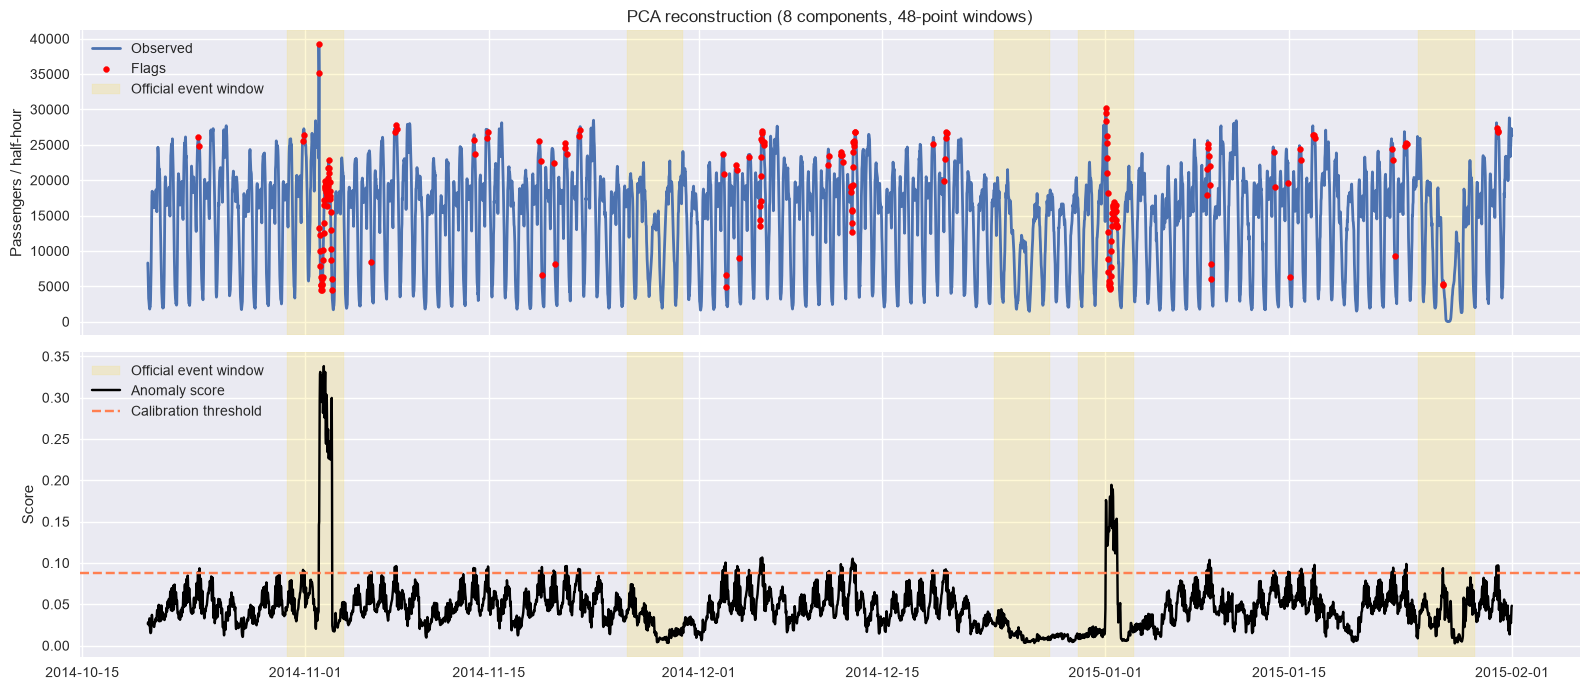

method                       PCA reconstruction
threshold                               0.08778
calibration_flag_fraction              0.008772
precision                                   0.5
recall                                   0.0928
f1                                       0.1565
average_precision                        0.2365
detected_events                               3
events                                        5
event_recall                                0.6
median_delay_h_detected                    44.5
false_flag_fraction                      0.0243
false_runs_per_30d                        20.74
dtype: object

In [32]:
reports["PCA reconstruction"] = evaluate_scores("PCA reconstruction", scores["PCA reconstruction"], labels,
                                               calibration_index, test_index, CFG.alpha)
plot_detector(y, labels, scores["PCA reconstruction"], reports["PCA reconstruction"]["threshold"],
              test_index, f"PCA reconstruction ({CFG.latent_dim} components, {CFG.window_size}-point windows)")
pd.Series(reports["PCA reconstruction"])

This code segment evaluates the performance of anomaly detection based on PCA reconstruction error and visualizes the results.

First, it calls the `evaluate_scores` function to assess the effectiveness of the "PCA reconstruction" scores in identifying true events. The arguments passed include: the name of the method ("PCA reconstruction"), the calculated anomaly scores (`scores["PCA reconstruction"]`), the ground truth event labels (`labels`), the calibration index, the test index, and the significance level `CFG.alpha`. The returned evaluation metrics are stored in the `reports` dictionary under the key "PCA reconstruction".

Next, it calls the `plot_detector` function to visualize the results of the anomaly detection process. It passes the original time series data (`y`), event labels (`labels`), the “PCA reconstruction” scores (`scores["PCA reconstruction"]`), the threshold determined during calibration (obtained from `reports["PCA reconstruction"]["threshold"]`), the test index, and a title for the plot that includes the number of principal components (`CFG.latent_dim`) and the window size (`CFG.window_size`).

Finally, it converts the evaluation metrics stored in `reports["PCA reconstruction"]` into a Pandas Series and prints it to display a concise summary of the method’s performance—including precision, recall, F1-score, average precision, detected events, and other relevant metrics. This provides a quantitative assessment of how well anomaly detection based on PCA reconstruction error performs in detecting anomalies compared to known events.

## Keras autoencoder

In [33]:
keras.utils.set_random_seed(CFG.SEED)
with keras.device(DEVICE):
    autoencoder = keras.Sequential([
        keras.Input(shape=(CFG.window_size,)),
        layers.Dense(CFG.hidden_units, activation="relu"),
        layers.Dense(CFG.latent_dim, activation="relu", name="bottleneck"),
        layers.Dense(CFG.hidden_units, activation="relu"),
        layers.Dense(CFG.window_size, activation="linear"),
    ], name="daily_window_autoencoder")
    autoencoder.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                        loss="mse", jit_compile=False)
autoencoder.to(DEVICE)
print(f"Actual parameter device: {next(autoencoder.parameters()).device}")
autoencoder.summary()

Actual parameter device: mps:0


Model: "daily_window_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 24)             │         1,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 8)              │           200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 24)             │           216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 48)             │         1,200 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,792 (10.91 KB)

 Trainable params: 2,792 (10.91 KB)

 Non-trainable params: 0 (0.00 B)

This code segment defines and compiles a Keras autoencoder model for anomaly detection based on sliding windows of the time series data.

First, it sets the random seed for Keras to `CFG.SEED` to ensure reproducibility. Then, using a `with keras.device(DEVICE):` context manager, it ensures that all subsequent Keras operations are performed on the specified device (`DEVICE`, which is either "mps" or "cpu").

It defines a sequential autoencoder model named “daily_window_autoencoder” using `keras.Sequential`. The model consists of:
- An input layer with a shape matching the window size (`CFG.window_size`).
- A dense (fully connected) layer with `CFG.hidden_units` neurons and ReLU activation.
- A bottleneck layer with `CFG.latent_dim` neurons and ReLU activation, representing the compressed representation of the input data. This is named "bottleneck".
- Another dense layer with `CFG.hidden_units` neurons and ReLU activation.
- An output layer with `CFG.window_size` neurons and linear activation, reconstructing the original input.

The model is compiled using the Adam optimizer (with a learning rate of 0.001) and Mean Squared Error (MSE) as the loss function. The `jit_compile=False` argument disables just-in-time compilation for compatibility reasons.

The autoencoder is then moved to the specified device (`autoencoder.to(DEVICE)`). A message is printed confirming the actual device where the model parameters are located. Finally, a summary of the model architecture is displayed using `autoencoder.summary()`, providing an overview of the layers, output shapes, and number of trainable parameters. This prepares the autoencoder for training on the sliding window data to learn a compressed representation and reconstruct the original input.

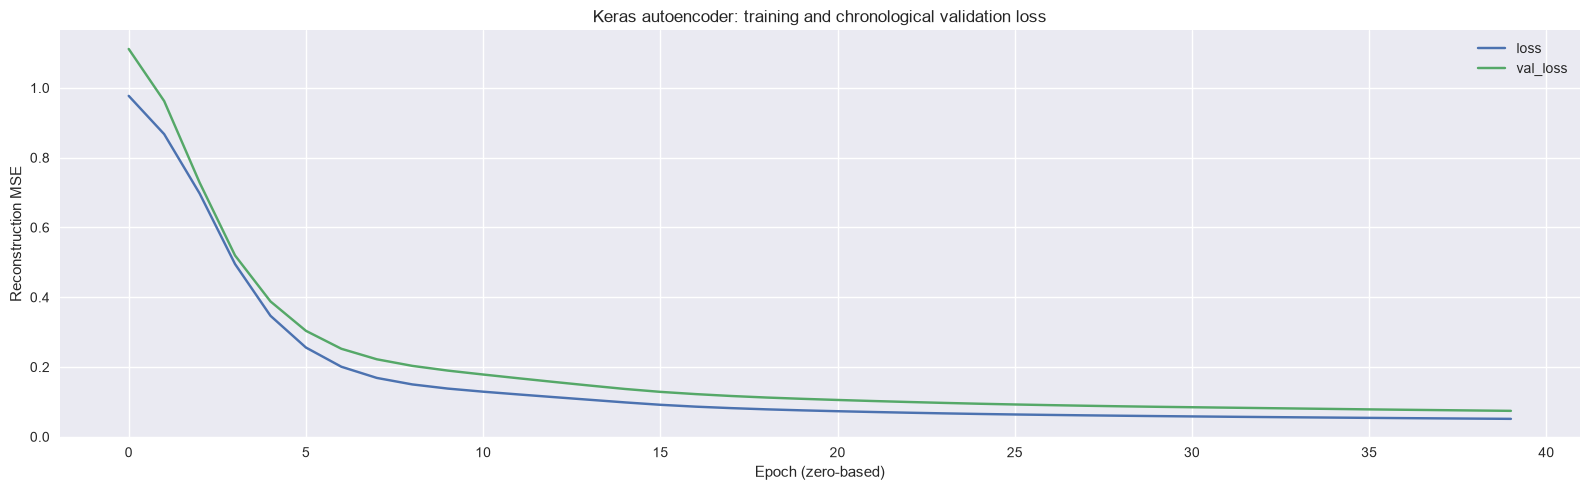

Epochs run: 40 | best validation epoch: 40


In [34]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=CFG.patience,
                                          restore_best_weights=True)
with keras.device(DEVICE):
    history = autoencoder.fit(
        X_windows[window_train_mask], X_windows[window_train_mask],
        validation_data=(X_windows[window_validation_mask], X_windows[window_validation_mask]),
        epochs=CFG.epochs, batch_size=CFG.batch_size, shuffle=False,
        callbacks=[early_stop], verbose=0,
    )
loss_history = pd.DataFrame(history.history)
ax = loss_history.plot(xlabel="Epoch (zero-based)", ylabel="Reconstruction MSE",
                        title="Keras autoencoder: training and chronological validation loss")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Epochs run: {len(loss_history)} | best validation epoch: {loss_history['val_loss'].idxmin() + 1}")

This code segment trains the Keras autoencoder model on the sliding window data and monitors its performance using a validation set.

First, it creates an `EarlyStopping` callback to prevent overfitting. This callback monitors the validation loss during training and stops training when the validation loss hasn't improved for `CFG.patience` epochs, restoring the weights from the epoch with the best validation loss.

Then, within a `with keras.device(DEVICE):` context manager, it trains the autoencoder using the `.fit()` method. The training data (`X_windows[window_train_mask]`) is used as both input and target (since an autoencoder learns to reconstruct its input). A validation set (`X_windows[window_validation_mask]`) is provided for monitoring performance during training.

The model is trained for `CFG.epochs` epochs with a batch size of `CFG.batch_size`. The `shuffle=False` argument ensures that the data is not shuffled, preserving the temporal order of the windows. The `callbacks` argument includes the `early_stop` callback to prevent overfitting and restore the best weights. Verbose output is suppressed (`verbose=0`).

The training history (including loss values for both training and validation sets) is stored in a Pandas DataFrame called `loss_history`. A plot of the training and validation losses over epochs is generated using `.plot()`, with appropriate labels and title. The legend, layout, and display are handled as before.

Finally, it prints information about the training process: the total number of epochs run (`len(loss_history)`) and the epoch number (starting from 1) where the validation loss reached its minimum value (`loss_history['val_loss'].idxmin() + 1`). This provides insights into how well the autoencoder learned to reconstruct the input data and when training should be stopped to avoid overfitting.

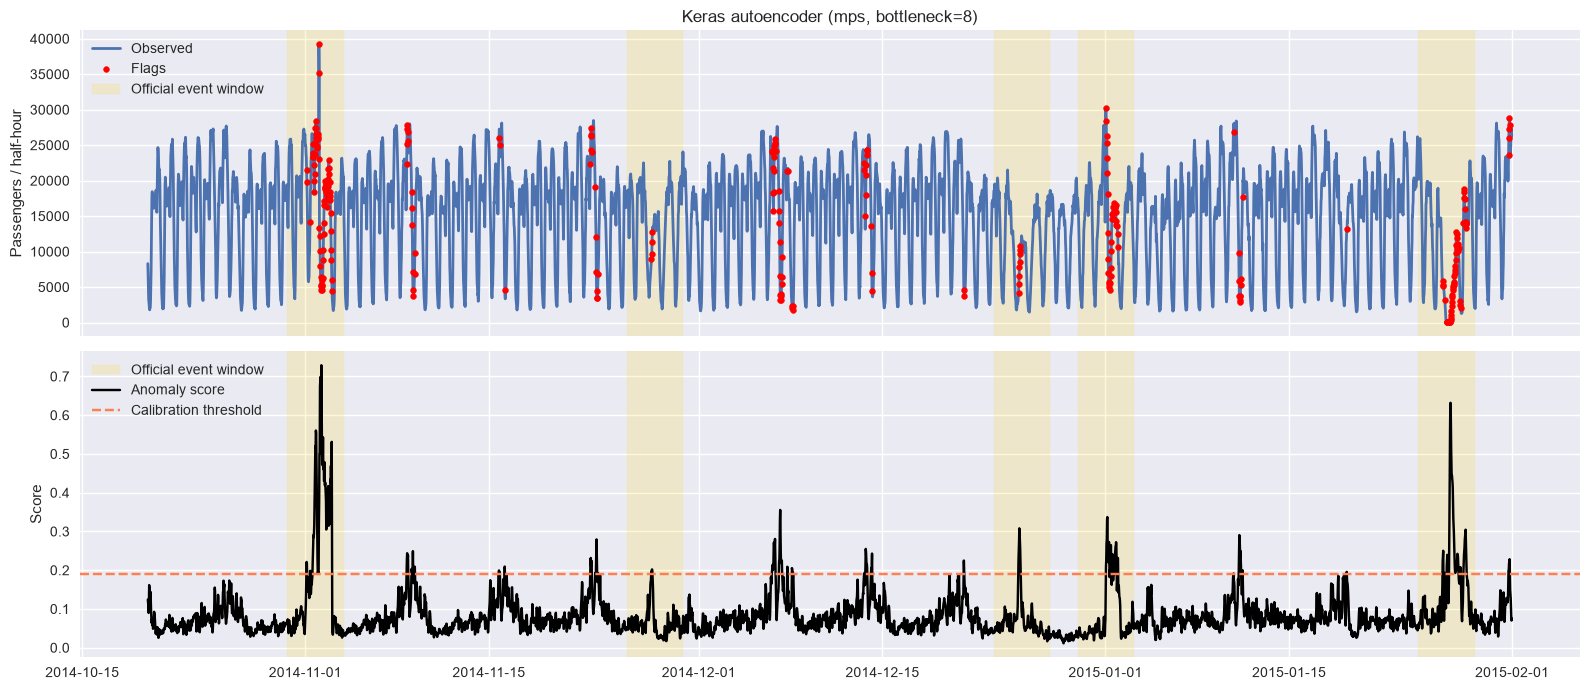

method                       Keras autoencoder
threshold                             0.191135
calibration_flag_fraction             0.008772
precision                               0.6582
recall                                  0.1749
f1                                      0.2763
average_precision                       0.3492
detected_events                              5
events                                       5
event_recall                               1.0
median_delay_h_detected                   45.5
false_flag_fraction                     0.0238
false_runs_per_30d                        9.46
dtype: object

In [35]:
with keras.device(DEVICE):
    ae_reconstruction = autoencoder.predict(X_windows, batch_size=CFG.batch_size, verbose=0)
scores["Keras autoencoder"] = pd.Series(
    np.mean((X_windows - ae_reconstruction) ** 2, axis=1), index=window_index
)
reports["Keras autoencoder"] = evaluate_scores("Keras autoencoder", scores["Keras autoencoder"], labels,
                                              calibration_index, test_index, CFG.alpha)
plot_detector(y, labels, scores["Keras autoencoder"], reports["Keras autoencoder"]["threshold"],
              test_index, f"Keras autoencoder ({DEVICE}, bottleneck={CFG.latent_dim})")
pd.Series(reports["Keras autoencoder"])

This code segment uses the trained Keras autoencoder to reconstruct the sliding window data, calculates reconstruction errors as anomaly scores, evaluates performance, and visualizes the results.

First, within a `with keras.device(DEVICE):` context manager, it uses the trained `autoencoder` to predict (reconstruct) the input data (`X_windows`) using `.predict()`. The batch size is set to `CFG.batch_size`, and verbose output is suppressed (`verbose=0`).

Anomaly scores are then calculated as the mean squared error (MSE) between the original sliding windows (`X_windows`) and their reconstructed versions (`ae_reconstruction`), averaged across all features within each window. These scores are stored in a Pandas Series called `scores["Keras autoencoder"]`, indexed by the `window_index`. Higher MSE values indicate larger reconstruction errors, suggesting potential anomalies.

Next, it calls the `evaluate_scores` function to assess the effectiveness of the "Keras autoencoder" anomaly scores in identifying true events. The arguments passed include: the name of the method ("Keras autoencoder"), the calculated anomaly scores (`scores["Keras autoencoder"]`), the ground truth event labels (`labels`), the calibration index, the test index, and the significance level `CFG.alpha`. The returned evaluation metrics are stored in the `reports` dictionary under the key "Keras autoencoder".

Then, it calls the `plot_detector` function to visualize the results of the anomaly detection process. It passes the original time series data (`y`), event labels (`labels`), the “Keras autoencoder” scores (`scores["Keras autoencoder"]`), the threshold determined during calibration (obtained from `reports["Keras autoencoder"]["threshold"]`), the test index, and a title for the plot that includes the device used (`DEVICE`) and the bottleneck dimension (`CFG.latent_dim`).

Finally, it converts the evaluation metrics stored in `reports["Keras autoencoder"]` into a Pandas Series and prints it to display a concise summary of the method’s performance—including precision, recall, F1-score, average precision, detected events, and other relevant metrics. This provides a quantitative assessment of how well anomaly detection based on Keras autoencoder reconstruction error performs in detecting anomalies compared to known events.

# Application: compare evidence, duration, and alert burden

In [36]:
comparison = pd.DataFrame(reports.values()).set_index("method")
print(f"Test window-membership prevalence: {labels.loc[test_index].mean():.3%}")
comparison[["average_precision", "precision", "recall", "f1", "detected_events", "events",
            "event_recall", "median_delay_h_detected", "false_flag_fraction", "false_runs_per_30d"]]

Test window-membership prevalence: 20.733%


,average_precision,precision,recall,f1,detected_events,events,event_recall,median_delay_h_detected,false_flag_fraction,false_runs_per_30d
method,,,,,,,,,,
Raw MAD,0.2543,0.4941,0.0406,0.0750,5,5,1.0,57.5,0.0109,8.01
Seasonal MAD,0.4976,0.7235,0.2502,0.3719,5,5,1.0,33.5,0.0250,12.01
Ridge residual,0.4791,0.6812,0.2415,0.3566,5,5,1.0,27.0,0.0296,29.48
Seasonal EWMA,0.5678,0.7923,0.2986,0.4337,5,5,1.0,44.5,0.0205,4.37
Isolation Forest,0.6074,0.7654,0.3372,0.4681,5,5,1.0,30.0,0.0270,16.74
PCA reconstruction,0.2365,0.5000,0.0928,0.1565,3,5,0.6,44.5,0.0243,20.74
Keras autoencoder,0.3492,0.6582,0.1749,0.2763,5,5,1.0,45.5,0.0238,9.46


This code segment consolidates the evaluation results from all anomaly detection methods and presents a comparative summary of their performance.

First, it creates a Pandas DataFrame called `comparison` by converting the dictionary of reports (`reports.values()`) into a DataFrame. The "method" column is set as the index of the DataFrame, allowing for easy comparison across different methods.

Next, it prints the prevalence of true events within the test dataset—the proportion of timestamps in the test index that are labeled as belonging to an event (`labels.loc[test_index].mean()`). This provides context for interpreting the performance metrics.

Finally, it selects and displays specific columns from the `comparison` DataFrame: "average_precision", "precision", "recall", "f1", "detected_events", "events", "event_recall", "median_delay_h_detected", "false_flag_fraction", and "false_runs_per_30d". This provides a concise table summarizing the key performance metrics for each anomaly detection method, allowing for direct comparison of their effectiveness in detecting anomalies while minimizing false alarms.

In [37]:
truth = labels.loc[test_index].to_numpy(dtype=bool)
edges = np.diff(np.r_[0, truth.astype(int), 0])
starts, stops = np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)
one_hit_per_window = np.zeros(len(test_index), dtype=bool)
one_hit_per_window[starts] = True
point_adjusted = one_hit_per_window.copy()
for start, stop in zip(starts, stops):
    if one_hit_per_window[start:stop].any():
        point_adjusted[start:stop] = True
adjustment_rows = []
for name, prediction in [("Actual one-hit flags", one_hit_per_window),
                         ("After point adjustment", point_adjusted)]:
    p, r, f, _ = precision_recall_fscore_support(truth, prediction, average="binary", zero_division=0)
    adjustment_rows.append({"evaluation": name, "positive_points_credited": int(prediction.sum()),
                            "precision": float(p), "recall": float(r), "f1": float(f)})
pd.DataFrame(adjustment_rows).set_index("evaluation").round(4)

,positive_points_credited,precision,recall,f1
evaluation,,,,
Actual one-hit flags,5,1.0,0.0048,0.0096
After point adjustment,1035,1.0,1.0000,1.0000


This code segment analyzes the performance of anomaly detection in terms of identifying event windows, and explores a post-processing adjustment to improve window-level accuracy.

First, it extracts the ground truth labels for the test set (`labels.loc[test_index]`) and converts them into a boolean NumPy array called `truth`. It then identifies the start and end indices of consecutive true events using `np.diff` and `np.flatnonzero`, similar to previous code sections.

Next, it creates a boolean array called `one_hit_per_window`, where `True` indicates that at least one anomaly was detected within each event window (identified by the start indices). This represents a simple "one-hit" criterion for detecting events.

A copy of `one_hit_per_window` is made and assigned to `point_adjusted`. The code then iterates through each event window, and if any anomaly was detected within that window in `one_hit_per_window`, it sets all points within that window to `True` in `point_adjusted`. This adjustment ensures that once an event window is identified as containing at least one anomaly, the entire window is considered a detection.

Finally, it calculates precision, recall, and F1-score for both the original "one-hit" flags (`one_hit_per_window`) and the adjusted flags (`point_adjusted`), comparing them to the ground truth `truth`. The results are stored in a list of dictionaries called `adjustment_rows`, including the number of positive points credited (i.e., the number of True values) for each method. A Pandas DataFrame is created from this list, with "evaluation" as the index, and the precision, recall, and F1-score are rounded to four decimal places and displayed. This allows for a comparison of the impact of the point adjustment on window-level detection performance.

In [38]:
ALPHA_GRID = [0.001, 0.005, 0.01, 0.025, 0.05]
threshold_sensitivity = pd.DataFrame([
    {"alpha": alpha, **evaluate_scores(CFG.operational_method, scores[CFG.operational_method],
                                       labels, calibration_index, test_index, alpha)}
    for alpha in ALPHA_GRID
]).set_index("alpha")
threshold_sensitivity[["threshold", "calibration_flag_fraction", "precision", "recall",
                       "detected_events", "median_delay_h_detected", "false_flag_fraction", "false_runs_per_30d"]]

,threshold,calibration_flag_fraction,precision,recall,detected_events,median_delay_h_detected,false_flag_fraction,false_runs_per_30d
alpha,,,,,,,,
0.001,inf,0.000000,0.0000,0.0000,0,NaN,0.0000,0.00
0.005,8.320360,0.003289,0.7788,0.2348,5,33.5,0.0174,8.01
0.010,7.768952,0.008772,0.7235,0.2502,5,33.5,0.0250,12.01
0.025,6.996699,0.023026,0.6258,0.2715,5,30.0,0.0425,18.92
0.050,6.178026,0.048246,0.5528,0.3034,5,29.0,0.0642,25.84


This code segment performs a sensitivity analysis of the anomaly detection threshold by evaluating performance across a range of alpha values.

First, it defines `ALPHA_GRID` as a list of alpha values to be tested—[0.001, 0.005, 0.01, 0.025, 0.05]. These alpha values control the significance level used in determining the anomaly detection threshold.

Next, it creates a Pandas DataFrame called `threshold_sensitivity` using a list comprehension. For each alpha value in `ALPHA_GRID`, it calls the `evaluate_scores` function with the specified alpha and stores the returned evaluation metrics in a dictionary. The dictionary is then combined with the alpha value itself to create a row in the DataFrame. The "alpha" column is set as the index of the DataFrame.

Finally, it selects and displays specific columns from the `threshold_sensitivity` DataFrame: "threshold", "calibration_flag_fraction", "precision", "recall", "detected_events", "median_delay_h_detected", "false_flag_fraction", and "false_runs_per_30d". This provides a table summarizing how these performance metrics change as the alpha value (and therefore the threshold) is varied. This allows for an assessment of the trade-offs between sensitivity and specificity in anomaly detection, helping to choose an optimal alpha value based on the specific application requirements.

# Change detection


## Online CUSUM

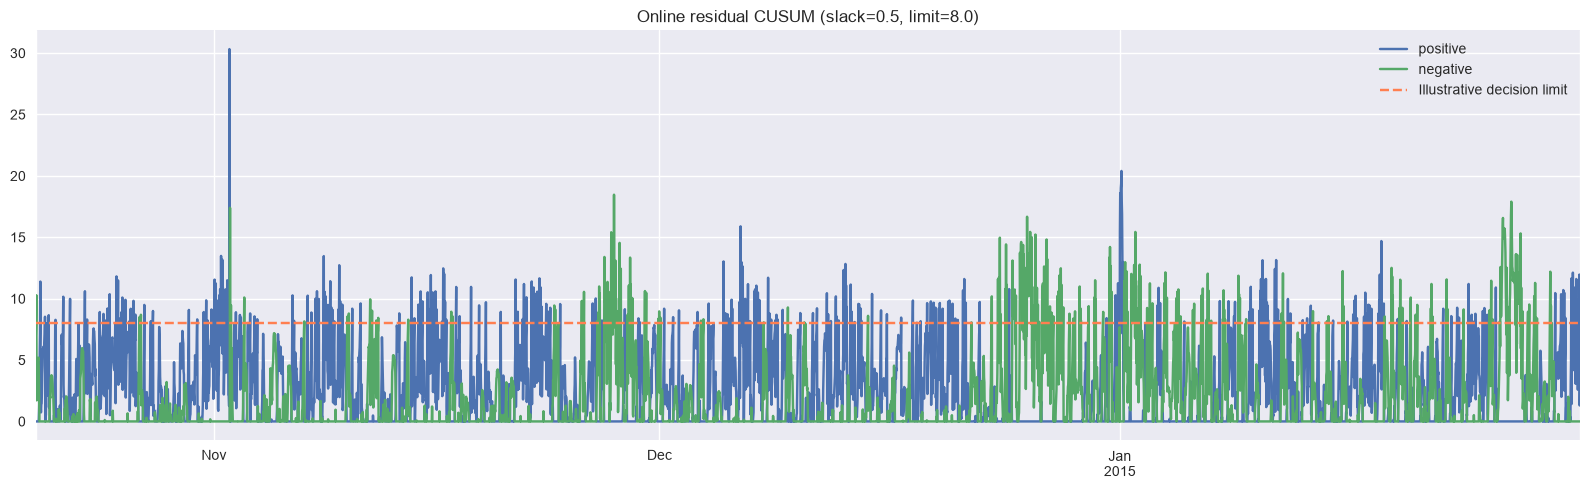

reset_accumulators_alarm_points     682
no_reset_alarm_points              4992
dtype: int64

In [39]:
monitoring_index = forecast_residual.index[forecast_residual.index >= calibration_index.min()]
monitoring_residual = robust_standardize(forecast_residual.loc[monitoring_index],
                                        forecast_residual.loc[forecast_train])
cusum_reset = cusum_path(monitoring_residual, CFG.cusum_slack, CFG.cusum_limit, True)
cusum_no_reset = cusum_path(monitoring_residual, CFG.cusum_slack, CFG.cusum_limit, False)
ax = cusum_reset[["positive", "negative"]].loc[test_index].plot(
    title=f"Online residual CUSUM (slack={CFG.cusum_slack}, limit={CFG.cusum_limit})", xlabel=""
)
ax.axhline(CFG.cusum_limit, color="coral", linestyle="--", label="Illustrative decision limit")
ax.legend()
plt.tight_layout()
plt.show()
pd.Series({"reset_accumulators_alarm_points": int(cusum_reset.loc[test_index, "alarm"].sum()),
           "no_reset_alarm_points": int(cusum_no_reset.loc[test_index, "alarm"].sum())})

This code segment implements and visualizes a Cumulative Sum (CUSUM) control chart for online anomaly detection based on the forecast residuals. It compares two CUSUM implementations: one that resets accumulators after an alarm and another that does not.

First, it defines `monitoring_index` as the portion of the `forecast_residual` index starting from the minimum date in the calibration period. This represents the data used for online monitoring. The corresponding residuals are extracted into `monitoring_residual`. These residuals are then robustly standardized using the training data as a reference.

Next, it calculates two CUSUM paths:
- `cusum_reset`: A CUSUM path where the accumulators are reset to zero after each alarm is triggered (`reset_on_alarm=True`).
- `cusum_no_reset`: A CUSUM path where the accumulators continue accumulating even after an alarm (`reset_on_alarm=False`).

A plot of the "positive" and "negative" accumulators from the `cusum_reset` series is generated for the test index. The plot includes a title indicating the slack and limit values used in the CUSUM algorithm, as well as axis labels. A horizontal line representing the decision limit (`CFG.cusum_limit`) is added to the plot for reference.

Finally, it prints a summary of the number of alarm points triggered by each CUSUM implementation (with and without resetting accumulators) during the test period. This allows for comparison of their sensitivity and responsiveness to anomalies. The visualization helps assess how well the CUSUM control chart detects deviations from expected behavior in real-time.

## Offline segmentation

In [40]:
daily_features = pd.DataFrame({
    "residual_mean": seasonal_residual.resample("1D").mean(),
    "log_residual_std": np.log(seasonal_residual.resample("1D").std().clip(lower=1.0)),
    "count": seasonal_residual.resample("1D").count(),
})
daily_features = daily_features.loc[daily_features["count"] == CFG.daily_period].drop(columns="count")
daily_train = daily_features.index[daily_features.index < pd.Timestamp(CFG.train_end)]
daily_scaler = StandardScaler().fit(daily_features.loc[daily_train])
daily_signal = daily_scaler.transform(daily_features)
daily_features.head(3)

,residual_mean,log_residual_std
timestamp,,
2014-07-01,709.083333,6.743087
2014-07-02,-89.479167,7.296205
2014-07-03,-819.166667,7.807751


This code segment creates daily aggregated features from the seasonal residuals and prepares them for anomaly detection using a scaling transformation.

First, it creates a Pandas DataFrame called `daily_features` by resampling the `seasonal_residual` time series to a daily frequency ("1D"). It calculates three features:
- `"residual_mean"`: The mean of the seasonal residual for each day.
- `"log_residual_std"`: The natural logarithm of the standard deviation of the seasonal residual for each day, clipped at 1.0 to avoid taking the log of zero. This helps stabilize variance and handle potential outliers in the standard deviation.
- `"count"`: The number of observations contributing to each daily aggregation.

The code then filters `daily_features` to include only days where the count is equal to `CFG.daily_period`, ensuring that all days have a complete set of observations. The "count" column is dropped after filtering.

Next, it defines `daily_train` as the index corresponding to the training period for the daily features. A `StandardScaler` object is created and fitted to the training data (`daily_features.loc[daily_train]`).

Finally, the scaler is used to transform the entire `daily_features` DataFrame into a scaled representation called `daily_signal`. This scaling ensures that all features have zero mean and unit variance, which can improve the performance of subsequent anomaly detection algorithms. The first three rows of the original `daily_features` are displayed for inspection.

In [41]:
segmentations = {}
segmentation_rows = []
for multiplier in CFG.penalty_multipliers:
    penalty = multiplier * np.log(len(daily_signal))
    ends = optimal_partition(daily_signal, penalty, min_size=CFG.min_segment_days)
    segmentations[multiplier] = ends
    segmentation_rows.append({"penalty_multiplier": multiplier, "penalty": penalty,
                              "segments": len(ends), "internal_boundaries": len(ends) - 1})
pd.DataFrame(segmentation_rows).set_index("penalty_multiplier").round(3)

,penalty,segments,internal_boundaries
penalty_multiplier,,,
2.0,10.741,11,10
4.0,21.483,9,8
8.0,42.965,4,3


This code segment performs a series of optimal segmentations on the daily features using different penalty values and analyzes the resulting segmentation structures.

First, it initializes an empty dictionary called `segmentations` to store the end points of each segmentation for different penalty multipliers. It also initializes an empty list called `segmentation_rows` to accumulate information about each segmentation result.

The code then iterates through a range of penalty multipliers defined in `CFG.penalty_multipliers`. For each multiplier, it calculates a penalty value by multiplying the multiplier with the natural logarithm of the length of the `daily_signal`. This dynamic penalty scaling adjusts the cost of adding new segments based on the size of the dataset.

The `optimal_partition` function is called to perform an optimal segmentation of the `daily_signal` using the calculated penalty and a minimum segment size specified by `CFG.min_segment_days`. The resulting end points of the segments are stored in the `segmentations` dictionary, keyed by the corresponding penalty multiplier.

Information about each segmentation result is appended to the `segmentation_rows` list as a dictionary containing:
- `"penalty_multiplier"`: The penalty multiplier used for the segmentation.
- `"penalty"`: The calculated penalty value.
- `"segments"`: The number of segments identified in the segmentation.
- `"internal_boundaries"`: The number of internal boundaries between segments (one less than the number of segments).

Finally, a Pandas DataFrame is created from the `segmentation_rows` list, with "penalty_multiplier" set as the index. The DataFrame is then displayed, rounded to three decimal places, providing a summary of the segmentation results for each penalty multiplier. This allows for comparison of different segmentation structures and selection of an appropriate penalty value based on the desired level of granularity.

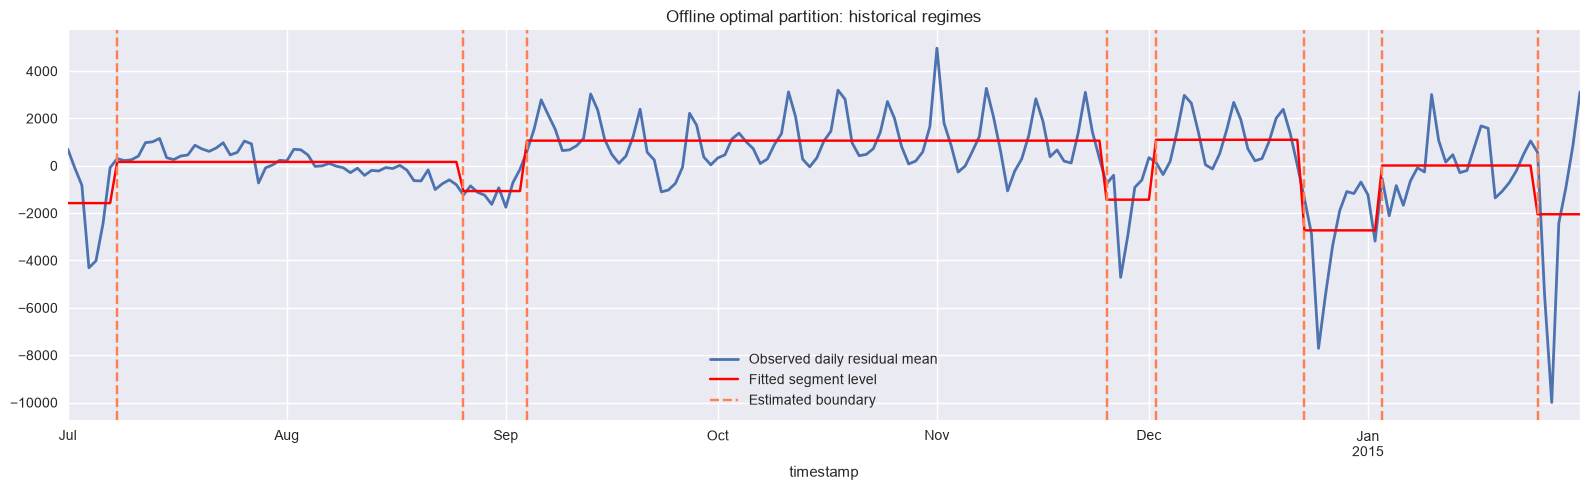

,estimated_boundary
0,2014-07-08
1,2014-08-26
2,2014-09-04
3,2014-11-25
4,2014-12-02
5,2014-12-23
6,2015-01-03
7,2015-01-25


In [42]:
selected_ends = segmentations[CFG.selected_penalty]
segmented_mean = pd.Series(index=daily_features.index, dtype=float)
start = 0
for stop in selected_ends:
    segmented_mean.iloc[start:stop] = daily_features["residual_mean"].iloc[start:stop].mean()
    start = stop
ax = daily_features["residual_mean"].plot(linewidth=2, label="Observed daily residual mean",
                                         title="Offline optimal partition: historical regimes", xlabel="")
segmented_mean.plot(ax=ax, color="red", label="Fitted segment level")
for number, stop in enumerate(selected_ends[:-1]):
    ax.axvline(daily_features.index[stop], color="coral", linestyle="--",
               label="Estimated boundary" if number == 0 else None)
ax.legend()
plt.tight_layout()
plt.show()
pd.DataFrame({"estimated_boundary": daily_features.index[np.array(selected_ends[:-1], dtype=int)]})

This code segment visualizes the optimal segmentation of the daily residual mean, highlighting the identified historical regimes.

First, it retrieves the end points of the selected segmentation from the `segmentations` dictionary using the penalty multiplier specified by `CFG.selected_penalty`. These end points define the boundaries between segments.

Next, it creates a Pandas Series called `segmented_mean`, initialized with NaN values and indexed by the index of `daily_features`. The code then iterates through the selected end points, calculating the mean of the "residual_mean" within each segment (from the start to the current stop point) and assigning that mean value to all data points within that segment in the `segmented_mean` series. This effectively creates a piecewise-constant representation of the daily residual mean, where each segment has a constant value equal to its average.

A plot is generated using Matplotlib, displaying the original "residual_mean" time series as a line plot with label “Observed daily residual mean”. The `segmented_mean` series is then overlaid on the same plot as a red line labeled “Fitted segment level”. This visually represents the piecewise-constant approximation of the original data.

Vertical lines are added to the plot at each estimated boundary (defined by the selected end points), using a coral dashed linestyle. A label "Estimated boundary" is added only to the first vertical line to avoid redundancy in the legend.

The plot includes a title ("Offline optimal partition: historical regimes"), an x-axis label, and a legend for clarity. The layout is adjusted using `plt.tight_layout()`, and the plot is displayed.

Finally, a Pandas DataFrame is created containing the estimated boundary dates (converted to integers) and displayed. This provides a tabular representation of the identified segment boundaries.

# Application: turn scores into a reviewable alert log


In [43]:
operating_threshold = reports[CFG.operational_method]["threshold"]
raw_flags = scores[CFG.operational_method].loc[test_index] > operating_threshold
persistent = raw_flags.rolling(CFG.persistence_window, min_periods=CFG.persistence_window).sum() >= CFG.persistence_hits
cooldown = pd.Timedelta(CFG.cooldown)
last_notice = test_index.min() - cooldown
alert_times = []
for timestamp, candidate in persistent.items():
    if candidate and timestamp - last_notice >= cooldown:
        alert_times.append(timestamp)
        last_notice = timestamp
alerts = pd.DataFrame(index=pd.DatetimeIndex(alert_times, name="timestamp"))
alerts["passengers"] = y.reindex(alerts.index)
alerts["score"] = scores[CFG.operational_method].reindex(alerts.index)
alerts["inside_official_window"] = labels.reindex(alerts.index)
print(f"Method: {CFG.operational_method} | raw flagged points: {raw_flags.sum()} | notification records: {len(alerts)}")
alerts.head(10)

Method: Seasonal MAD | raw flagged points: 358 | notification records: 54


,passengers,score,inside_official_window
timestamp,,,
2014-11-01 02:30:00,21459.0,8.231741,True
2014-11-01 10:00:00,19066.0,8.750797,True
2014-11-01 19:00:00,28398.0,8.645298,True
2014-11-02 01:30:00,35212.0,22.437543,True
2014-11-08 12:00:00,22352.0,8.393506,False
2014-11-08 19:00:00,27898.0,7.941970,False
2014-11-22 11:30:00,22981.0,9.354251,False
2014-11-26 22:00:00,17170.0,9.544150,True
2014-11-27 07:00:00,5955.0,10.811545,True


This code segment implements a post-processing step to filter anomaly flags based on persistence and cooldown periods, generating a list of actionable alerts.

First, it retrieves the operating threshold from the reports dictionary using `CFG.operational_method`. It then creates a boolean series called `raw_flags` indicating which points in the test index exceed this threshold.

Next, it applies a rolling window to the `raw_flags` series with a size specified by `CFG.persistence_window`, requiring at least `CFG.persistence_hits` consecutive flags within that window to be considered persistent. This helps filter out spurious anomalies and focus on sustained deviations from normal behavior. The result is stored in the `persistent` series.

A cooldown period is defined using `pd.Timedelta(CFG.cooldown)`. A variable `last_notice` is initialized to a time before the test index begins, ensuring that the first alert can be triggered. An empty list called `alert_times` is created to store the timestamps of generated alerts.

The code then iterates through the `persistent` series. If a point is flagged as persistent (`candidate`) and the time since the last alert (`timestamp - last_notice`) exceeds the cooldown period, it's considered an actionable alert. The timestamp is added to the `alert_times` list, and `last_notice` is updated to the current timestamp.

Finally, a Pandas DataFrame called `alerts` is created with the alert timestamps as its index. It includes columns for the passenger count (`passengers`), anomaly score (`score`), and whether the alert falls within an officially labeled event window (`inside_official_window`). The code prints the number of raw flagged points and the number of generated alerts, providing a summary of the filtering process. The first 10 rows of the `alerts` DataFrame are displayed for inspection. This provides a refined set of anomaly detections that are both persistent and spaced out in time, making them more likely to represent genuine events requiring attention.

In [44]:
event_review_rows = []
for event in event_windows.itertuples(index=False):
    event_index = test_index[(test_index >= event.start) & (test_index <= event.end)]
    event_flags = raw_flags.reindex(event_index)
    notices = alerts.index[(alerts.index >= event.start) & (alerts.index <= event.end)]
    hits = event_index[event_flags.to_numpy()]
    event_review_rows.append({
        "event": event.event, "labeled_half_hours": len(event_index),
        "raw_flag_fraction": float(event_flags.mean()), "notifications": len(notices),
        "first_raw_flag_delay_h": (hits[0] - event.start).total_seconds() / 3600 if len(hits) else np.nan,
        "first_notification_delay_h": (notices[0] - event.start).total_seconds() / 3600 if len(notices) else np.nan,
    })
event_review = pd.DataFrame(event_review_rows).set_index("event")
event_review.round(3)

,labeled_half_hours,raw_flag_fraction,notifications,first_raw_flag_delay_h,first_notification_delay_h
event,,,,,
NYC marathon,207,0.111,4,34.5,35.0
Thanksgiving,207,0.198,6,33.5,34.0
Christmas,207,0.386,10,9.5,10.5
New Year,207,0.266,8,9.5,10.0
Snowstorm,207,0.290,7,42.5,43.0


This code segment generates a review table summarizing the performance of anomaly detection during known event windows.

First, it initializes an empty list called `event_review_rows` to store information about each event. It then iterates through each row in the `event_windows` DataFrame using `itertuples(index=False)`.

For each event, it extracts the corresponding indices from the test index (`test_index`) that fall within the event's start and end times, storing them in `event_index`. It then reindexes the `raw_flags` series to match this `event_index`, creating `event_flags`. The alerts are similarly filtered by time.

It identifies the timestamps where raw anomaly flags were raised during the event (`hits`).

A dictionary containing information about each event is appended to the `event_review_rows` list, including:
- `"event"`: The name of the event.
- `"labeled_half_hours"`: The number of half-hour periods within the event window.
- `"raw_flag_fraction"`: The fraction of time points within the event window that were flagged as anomalies by the raw anomaly detection system.
- `"notifications"`: The number of alerts generated during the event window after applying persistence and cooldown filtering.
- `"first_raw_flag_delay_h"`: The delay (in hours) between the start of the event and the first raw anomaly flag, if any flags were raised.
- `"first_notification_delay_h"`: The delay (in hours) between the start of the event and the first alert generated, if any alerts were triggered.

Finally, a Pandas DataFrame called `event_review` is created from the `event_review_rows` list, with "event" set as the index. The DataFrame is then displayed, rounded to three decimal places, providing a concise summary of anomaly detection performance during each known event window. This allows for an assessment of how well the system detects anomalies associated with specific events and the timeliness of those detections.

In [45]:
method_guide = pd.DataFrame([
    ["Raw MAD", "Global level", "Misses calendar context"],
    ["Seasonal MAD", "Unexpected level for time of week", "Frozen profile and pooled residual scale"],
    ["Ridge residual", "Unexpected next reading given recent history", "Can quickly follow a sustained incident"],
    ["Seasonal EWMA", "Sustained signed departure", "Delay and lingering alarms"],
    ["Isolation Forest", "Unusual combinations of trailing features", "Feature choice and training contamination"],
    ["PCA / Keras AE", "Poorly reconstructed daily windows", "Can reconstruct anomalies; window smearing"],
    ["CUSUM", "Sequential evidence of a shifted residual process", "Reference assumptions and reset policy"],
    ["Offline partition", "Historical level / scale regimes", "Uses future observations; no online warning time"],
], columns=["method", "useful_question", "main_caution"]).set_index("method")
runtime = pd.Series({"python": platform.python_version(), "python_executable": sys.executable,
                     "numpy": np.__version__, "scikit-learn": version("scikit-learn"),
                     "statsmodels": version("statsmodels"), "matplotlib": version("matplotlib"),
                     "pandas": pd.__version__, "keras": keras.__version__, "torch": torch.__version__,
                     "backend": keras.backend.backend(),
                     "actual_model_device": str(next(autoencoder.parameters()).device),
                     "data_revision": CFG.nab_revision, "seed": CFG.SEED})
print(runtime.to_string())
method_guide

python                                                            3.12.8
python_executable      /Users/kbanachewicz/Documents/time-series-with...
numpy                                                              2.4.6
scikit-learn                                                       1.8.0
statsmodels                                                       0.14.6
matplotlib                                                        3.11.0
pandas                                                             3.0.3
keras                                                             3.15.0
torch                                                             2.12.1
backend                                                            torch
actual_model_device                                                mps:0
data_revision                   ea702d75cc2258d9d7dd35ca8e5e2539d71f3140
seed                                                                  42


,useful_question,main_caution
method,,
Raw MAD,Global level,Misses calendar context
Seasonal MAD,Unexpected level for time of week,Frozen profile and pooled residual scale
Ridge residual,Unexpected next reading given recent history,Can quickly follow a sustained incident
Seasonal EWMA,Sustained signed departure,Delay and lingering alarms
Isolation Forest,Unusual combinations of trailing features,Feature choice and training contamination
PCA / Keras AE,Poorly reconstructed daily windows,Can reconstruct anomalies; window smearing
CUSUM,Sequential evidence of a shifted residual process,Reference assumptions and reset policy
Offline partition,Historical level / scale regimes,Uses future observations; no online warning time


This code segment provides a summary of the methods used in the analysis and their key characteristics, along with runtime environment information.

First, it creates a Pandas DataFrame called `method_guide` containing descriptions of each anomaly detection method employed. The DataFrame has three columns: "method" (the name of the method), "useful_question" (a description of the type of anomalies the method is good at detecting), and "main_caution" (a potential limitation or consideration when using the method). The "method" column is set as the index of the DataFrame. This provides a quick reference guide to help understand the strengths and weaknesses of each approach.

Next, it creates a Pandas Series called `runtime` containing information about the software environment in which the analysis was performed. This includes versions of Python, NumPy, scikit-learn, statsmodels, matplotlib, pandas, Keras, and Torch, as well as the Keras backend being used, the device where the autoencoder model is running, the data revision used (from `CFG.nab_revision`), and the random seed (`CFG.SEED`).

Finally, it prints the contents of the `runtime` Series to the console using `to_string()`, providing a complete record of the software environment for reproducibility. The `method_guide` DataFrame is then displayed, offering a concise overview of the different anomaly detection methods used in the analysis and their key characteristics.